# TP CNN 2026 — Ouvrir la boîte noire d'un réseau convolutif

**ELISA Aerospace · 5e année · 3 h sur Google Colab · noté**

Dans le cours, vous avez vu *comment* un CNN est construit et *à quoi* il sert. Dans ce TP, vous allez ouvrir un vrai réseau et regarder ce qu'il calcule, couche par couche, sur les photos du cours. Puis vous le ferez apprendre une petite tâche aéronautique (avion / drone / oiseau), et vous chercherez où il regarde, quand il se trompe, et comment le tromper.

## Règles du jeu

> **Vous pouvez utiliser une IA pour écrire ou corriger du code.** Le code n'est pas noté.
> Vous êtes notés **uniquement** sur les cellules **✍️ Réponse** : vos prédictions avant d'exécuter, vos observations sur *vos propres* figures, vos explications.
> Une réponse générique, qui pourrait avoir été écrite sans regarder la figure obtenue, vaut **zéro**.
> Une prédiction fausse mais assumée et expliquée vaut la note pleine.

Types de cellules :

| Marque | Sens |
|---|---|
| 🔧 **Fournie** | s'exécute telle quelle, lisez-la quand même |
| ✏️ **À compléter** | quelques lignes à écrire ; une cellule *Solution* repliée suit, à ouvrir après 5 min d'essai |
| ✍️ **Réponse Rn** | texte libre, **noté** |
| 🎁 **Bonus** | hors barème |

Plan et temps indicatif :

| Bloc | Question | Temps | Où |
|---|---|---|---|
| 1 | Que fait vraiment une convolution ? | 25 min | séance |
| 2 | Que voit chaque couche ? | 35 min | séance |
| 3 | Pourquoi le transfer learning marche ? | 40 min | séance |
| 4 | Où regarde le réseau, et peut-on le tromper ? | 40 min | séance jusqu'à R9, puis maison |
| 5 | Et pour la détection ? | 25 min | maison |
| S | Synthèse | 15 min | maison |

### Comment lire ce notebook

Ce TP est aussi un cours. Chaque section suit le même schéma :
- une **figure** ou une animation du cours, et deux ou trois phrases qui rappellent la notion ;
- ⚠️ un piège à éviter, s'il y en a un ;
- 👀 **À regarder** : ce qu'il faut observer dans la sortie. Ce sont ces observations qui nourrissent vos Réponses ;
- un bloc replié **Détail du code et documentation** : le code expliqué ligne à ligne et les liens vers la documentation officielle. Ouvrez-le si une fonction vous est inconnue.

Notation des tenseurs : `(B, C, H, W)` = nombre d'images, canaux, hauteur, largeur. Une image seule a la forme `(1, 3, 224, 224)`.

**Travail en binôme.** Chaque binôme a un numéro qui personnalise ses données (bloc 0). Pensez à apporter **une photo d'avion de votre choix** (bloc 2, bonus).

<details><summary><b>Crédits des images et des modèles</b></summary>
<ul>
<li>Photo de l'A380 : Axwel (Flickr), licence <a href="https://creativecommons.org/licenses/by/2.0/">CC BY 2.0</a>, via <a href="https://commons.wikimedia.org/wiki/File:Airbus_A380_blue_sky.jpg">Wikimedia Commons</a>.</li>
<li>Image de la famille A320 en formation : © Airbus (Computer Graphic by i3m), utilisée avec l'autorisation d'Airbus.</li>
<li>Jeu avion / drone / oiseau : échantillon de trois jeux Kaggle de nelyg8002000, licence CC0 (domaine public).</li>
<li>ResNet-50 : poids ImageNet de torchvision. YOLO11n : Ultralytics, licence AGPL-3.0, poids téléchargés au premier lancement.</li>
</ul>
</details>

---
## Bloc 0 — Mise en place (10 min)

### 0.1 🔧 Bibliothèques et GPU

Un réseau de neurones passe son temps à multiplier des matrices : un GPU en fait des milliers en parallèle. Activez-le **avant** de lancer la première cellule : menu *Exécution → Modifier le type d'exécution → T4 GPU*. Changer de type d'exécution efface les variables.

> 👀 **À regarder** : la dernière ligne doit afficher `device : cuda`.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>La cellule installe <code>ultralytics</code> (YOLO, bloc 5) si besoin ; le reste est déjà sur Colab.</li>
<li>Bibliothèques principales : <b>PyTorch</b> (<code>torch</code>) pour les tenseurs et réseaux, <b>torchvision</b> pour les modèles pré-entraînés et les transformations d'images, <b>Pillow</b> (<code>PIL</code>) pour ouvrir et modifier des images.</li>
<li><code>DEVICE</code> vaut <code>'cuda'</code> (GPU NVIDIA, Colab), <code>'mps'</code> (GPU Apple) ou <code>'cpu'</code>. Partout, <code>.to(DEVICE)</code> envoie un modèle ou un tenseur sur ce device : modèle et entrées doivent être au même endroit.</li>
</ul>
📖 <a href="https://docs.pytorch.org/tutorials/beginner/basics/intro.html">PyTorch, Learn the Basics</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.cuda.is_available.html">torch.cuda.is_available</a> · <a href="https://pillow.readthedocs.io/en/stable/reference/Image.html">Pillow, module Image</a>
</details>

In [1]:
import sys, subprocess, importlib
for pkg in ['ultralytics']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

import os, json, math, random, time, zipfile, glob
from pathlib import Path
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image, ImageFilter, ImageDraw
import matplotlib.pyplot as plt

DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| device :', DEVICE)
if DEVICE == 'cpu':
    print("⚠️ Pas de GPU : le bloc 3 sera lent. Activez le GPU (Exécution → Modifier le type d'exécution) ou utilisez les courbes de secours.")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device : cuda


### 0.2 🔧 Les données

Rien à faire : la cellule **télécharge les données** depuis le dépôt GitHub du cours (un zip d'environ 10 Mo) et les décompresse. Si vous avez déjà le zip `TP_CNN_2026.zip`, déposez-le dans le panneau *Fichiers* de Colab : la cellule l'utilisera à la place.

| Dossier | Contenu | Bloc |
|---|---|---|
| `data/photos/` | A380, formation A320, masque de l'A380, patch adversarial | 1, 2, 4, 5 |
| `data/aero3/` | 900 photos avion / drone / oiseau (`train/` et `val/`) | 3, 4 |
| `data/curves/` | courbes d'entraînement de secours | 3 |

> ⚠️ **Attention** · L'espace de fichiers de Colab est effacé quand la session se termine. Au retour, relancez simplement les cellules depuis le début : les données seront retéléchargées.

> 👀 **À regarder** : la sortie doit lister `['avion', 'drone', 'oiseau']`.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>find_data()</code> cherche un dossier <code>data/</code> déjà décompressé, sinon un zip déposé dans Colab, sinon le télécharge depuis GitHub (<code>urllib</code>), et en dernier recours le cherche dans votre Drive. Il le décompresse avec <code>zipfile</code>.</li>
<li>Les chemins sont des objets <code>Path</code> : on écrit <code>DATA / 'photos'</code> au lieu de concaténer des chaînes.</li>
</ul>
📖 <a href="https://docs.python.org/fr/3/library/pathlib.html">pathlib</a> · <a href="https://docs.python.org/fr/3/library/zipfile.html">zipfile</a> · <a href="https://docs.python.org/fr/3/library/urllib.request.html">urllib.request</a> · <a href="https://colab.research.google.com/notebooks/io.ipynb">fichiers et Drive dans Colab</a>
</details>

In [2]:
DATA_URL = 'https://github.com/ArtificialIntelligenceModules/DeepLearning-2026-2027/releases/download/tp-cnn/TP_CNN_2026.zip'

def find_data():
    for d in ['data', 'TP_CNN_2026/data', '/content/TP_CNN_2026/data', '/content/data', '../data']:
        if Path(d, 'photos', 'a380.jpg').exists(): return Path(d)
    zips = glob.glob('TP_CNN_2026*.zip') + glob.glob('/content/TP_CNN_2026*.zip')
    if not zips:                                   # pas de zip déposé : téléchargement depuis GitHub
        try:
            import urllib.request
            print('téléchargement des données depuis GitHub…')
            urllib.request.urlretrieve(DATA_URL, 'TP_CNN_2026.zip'); zips = ['TP_CNN_2026.zip']
        except Exception as e:
            print('téléchargement impossible :', e)
    if not zips:                                   # dernier recours : le zip dans votre Drive
        try:
            from google.colab import drive; drive.mount('/content/drive')
            zips = glob.glob('/content/drive/MyDrive/**/TP_CNN_2026*.zip', recursive=True)
        except Exception:
            pass
    assert zips, "Données introuvables : déposez TP_CNN_2026.zip dans Colab (panneau Fichiers) puis relancez."
    print('décompression de', zips[0]); zipfile.ZipFile(zips[0]).extractall('.')
    return find_data()

DATA = find_data()
PHOTOS, AERO3 = DATA / 'photos', DATA / 'aero3'
print('données :', DATA.resolve())
print('classes aero3 :', sorted(p.name for p in (AERO3 / 'train').iterdir()))

téléchargement des données depuis GitHub…
décompression de TP_CNN_2026.zip
données : /content/TP_CNN_2026/data
classes aero3 : ['avion', 'drone', 'oiseau']


### 0.3 ✏️ Votre numéro de binôme

Entrez votre numéro de binôme dans le champ à droite de la cellule, puis exécutez-la. Il fixe :
- la **graine aléatoire** : vos tirages (poids initiaux, ordre des images) sont reproductibles ;
- **`N_TRAIN`**, le nombre d'images d'entraînement par classe au bloc 3 (40, 80, 160 ou 240) ;
- **`CLASSE_CIBLE`**, la classe dont vous étudierez les erreurs au bloc 4.

Deux binômes n'ont donc pas les mêmes figures : vos réponses doivent décrire **les vôtres**.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>seed_all()</code> fixe la graine des trois générateurs utilisés : Python, NumPy et PyTorch.</li>
<li><code>#@param</code> est une fonction de Colab qui affiche un champ de saisie à côté du code.</li>
</ul>
📖 <a href="https://docs.pytorch.org/docs/stable/notes/randomness.html">reproductibilité dans PyTorch</a> · <a href="https://colab.research.google.com/notebooks/forms.ipynb">formulaires Colab</a>
</details>

In [3]:
BINOME = 8  #@param {type:"integer"}

SEED = 1000 + BINOME
N_TRAIN = [40, 80, 160, 240][BINOME % 4]          # images d'entraînement par classe au bloc 3
CLASSE_CIBLE = ['avion', 'drone', 'oiseau'][BINOME % 3]  # classe étudiée au bloc 4

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_all()
print(f'Binôme {BINOME} → SEED={SEED}, N_TRAIN={N_TRAIN} images/classe, CLASSE_CIBLE={CLASSE_CIBLE!r}')

Binôme 8 → SEED=1008, N_TRAIN=40 images/classe, CLASSE_CIBLE='oiseau'


### 0.4 🔧 Utilitaires d'affichage et prétraitement du cours

Un réseau pré-entraîné attend ses images exactement comme à son entraînement : **224 × 224 pixels**, valeurs **normalisées** avec la moyenne et l'écart-type d'ImageNet. Comme dans le cours, on **complète la photo en carré** avec la couleur du ciel avant de la réduire : le réseau voit tout l'avion, sans déformation ni recadrage.

| Fonction | Rôle |
|---|---|
| `show(img, title)` / `show_grid(imgs, titles)` | afficher une image, ou une grille d'images |
| `square_pad(img)` | compléter une image en carré avec la couleur du ciel |
| `to_input(img)` | image → tenseur `(1, 3, 224, 224)` normalisé, prêt pour ResNet |
| `denorm(t)` | l'inverse : tenseur → image affichable |

> 👀 **À regarder** : la deuxième image, c'est ce que le réseau verra vraiment.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Une image chargée par PIL puis NumPy a la forme <code>(H, W, 3)</code>. PyTorch veut les canaux en premier : <code>permute(2, 0, 1)</code> donne <code>(3, H, W)</code>, et <code>[None]</code> ajoute la dimension du batch.</li>
<li>Normaliser : diviser par 255 (valeurs entre 0 et 1), retirer la moyenne de chaque canal, diviser par son écart-type. Le réseau a appris avec des entrées centrées sur 0 ; des valeurs brutes fausseraient toutes ses activations.</li>
</ul>
📖 <a href="https://pillow.readthedocs.io/en/stable/reference/Image.html">Image.open, resize, paste</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.Tensor.permute.html">Tensor.permute</a> · <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html">plt.imshow</a> · <a href="https://docs.pytorch.org/vision/stable/models.html">normalisation des modèles torchvision</a>
</details>

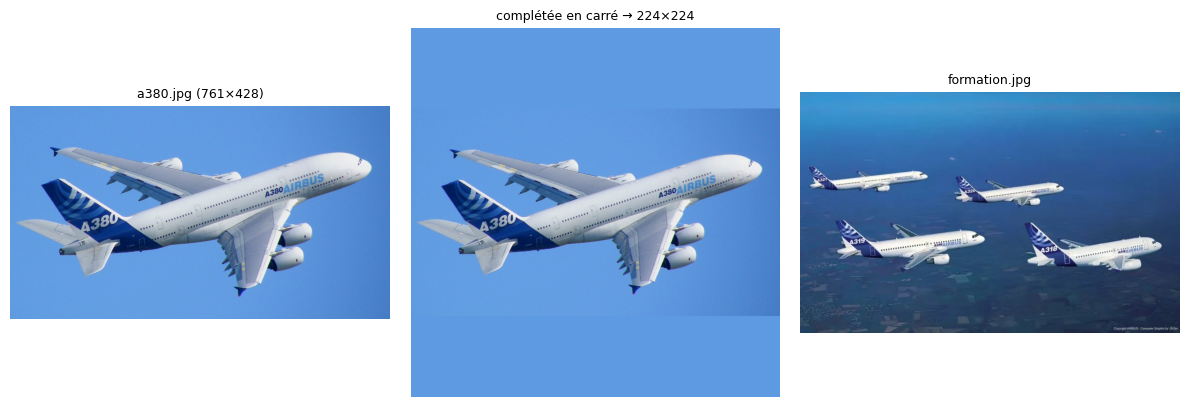

In [4]:
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def show(img, title=None, size=5, cmap=None):
    plt.figure(figsize=(size, size * 0.65)); plt.imshow(img, cmap=cmap); plt.axis('off')
    if title: plt.title(title)
    plt.show()

def show_grid(imgs, titles=None, ncols=4, size=2.6, cmap=None, suptitle=None):
    n = len(imgs); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    for i, ax in enumerate(np.array(axes).ravel()):
        ax.axis('off')
        if i < n:
            ax.imshow(imgs[i], cmap=cmap)
            if titles: ax.set_title(titles[i], fontsize=9)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

def square_pad(img):
    # complète la photo en carré avec la couleur moyenne du coin haut-gauche (le ciel)
    W, H = img.size; S = max(W, H)
    a = np.asarray(img); bg = tuple(int(v) for v in a[:max(5, H // 10), :max(5, W // 4)].reshape(-1, 3).mean(0))
    sq = Image.new('RGB', (S, S), bg); sq.paste(img, ((S - W) // 2, (S - H) // 2)); return sq

def to_input(img, size=224):
    # PIL -> tenseur (1,3,size,size) normalisé ImageNet, en passant par le carré
    t = torch.tensor(np.asarray(square_pad(img).resize((size, size), Image.BILINEAR))).permute(2, 0, 1).float()[None] / 255
    return (t - IMNET_MEAN) / IMNET_STD

def denorm(t):
    return (t.cpu() * IMNET_STD + IMNET_MEAN).clamp(0, 1)[0].permute(1, 2, 0).numpy()

A380 = Image.open(PHOTOS / 'a380.jpg').convert('RGB')
FORMATION = Image.open(PHOTOS / 'formation.jpg').convert('RGB')
show_grid([A380, square_pad(A380), FORMATION], ['a380.jpg (761×428)', 'complétée en carré → 224×224', 'formation.jpg'], ncols=3, size=4)

---
## Bloc 1 — Que fait vraiment une convolution ? (25 min)

On refait à la main ce que calcule la première couche d'un CNN : une somme pondérée de pixels voisins, répétée partout dans l'image. Rien de magique.

### 1.1 🔧 L'image est un tableau de nombres

<center>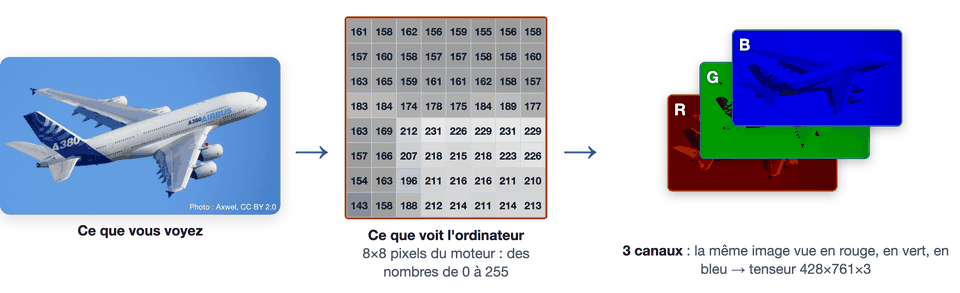</center>

Pour l'ordinateur, une photo couleur est un tableau **hauteur × largeur × 3 canaux** (rouge, vert, bleu), avec des valeurs de 0 à 255. Pour ce bloc, on passe en **niveaux de gris** : un seul canal, donc un tableau 2D de luminosités.

> ⚠️ **Attention** · PIL donne la taille d'une image en `(largeur, hauteur)` = `(761, 428)`. NumPy et PyTorch donnent la forme d'un tableau en `(hauteur, largeur)` = `(428, 761)`.

> 👀 **À regarder** : les 25 valeurs prises sur le fuselage. Sont-elles proches les unes des autres ou dispersées ?

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>A380.convert('L')</code> passe l'image en niveaux de gris (<i>L</i> pour luminance, une moyenne pondérée de R, V, B).</li>
<li><code>np.asarray(...)</code> transforme l'image en tableau NumPy ; <code>.astype(np.float32)</code> en nombres réels, car les calculs du bloc donneront des valeurs négatives.</li>
<li><code>gray[230:235, 380:385]</code> découpe un carré de 5×5 pixels : lignes 230 à 234, colonnes 380 à 384.</li>
</ul>
📖 <a href="https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert">Image.convert</a> · <a href="https://numpy.org/doc/stable/reference/generated/numpy.asarray.html">numpy.asarray</a> · <a href="https://numpy.org/doc/stable/user/basics.indexing.html">indexation NumPy</a>
</details>

shape : (428, 761) | min 8.0 | max 250.0
un carré de 5×5 pixels au milieu du fuselage :
 [[166 166 165 160 150]
 [161 155 157 158 151]
 [161 162 164 163 153]
 [162 159 161 159 152]
 [159 158 160 155 154]]


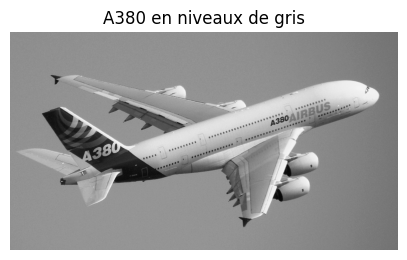

In [5]:
gray = np.asarray(A380.convert('L')).astype(np.float32)   # niveaux de gris, valeurs 0..255
print('shape :', gray.shape, '| min', gray.min(), '| max', gray.max())
print('un carré de 5×5 pixels au milieu du fuselage :\n', gray[230:235, 380:385].astype(int))
show(gray, 'A380 en niveaux de gris', cmap='gray')

### 1.2 🔧 Une convolution 2D écrite à la main

<center>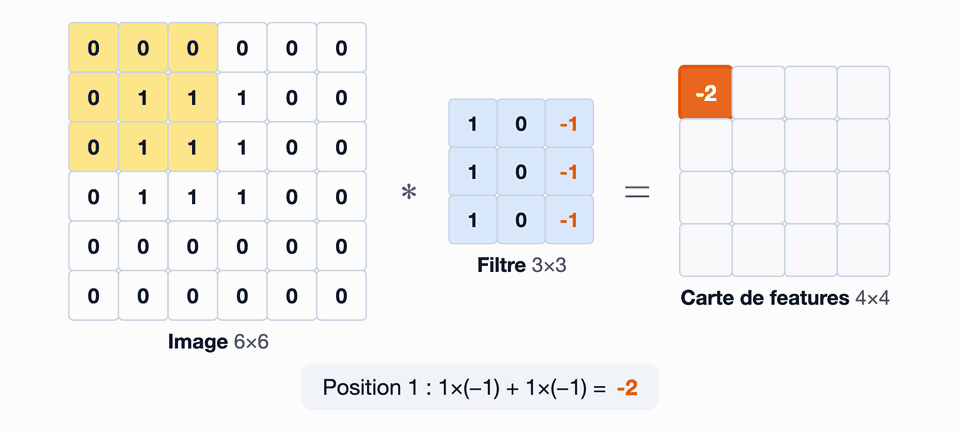</center>

Le **noyau** (ou filtre) 3×3 glisse sur l'image. À chaque position, on multiplie terme à terme et on additionne : on obtient **un** pixel de la **carte de features**. La fonction `conv2d_naive` fait exactement ça, avec deux boucles `for`.

La cellule définit aussi trois noyaux classiques :
- **Sobel vertical** : colonne de droite moins colonne de gauche, il répond aux **bords verticaux** ;
- **Sobel horizontal** : le même, tourné d'un quart de tour ;
- **flou** : la moyenne des 9 voisins.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Les deux boucles parcourent toutes les positions de sortie <code>(i, j)</code>. <code>patch</code> est le morceau d'image sous le noyau, <code>(patch * K).sum()</code> la somme pondérée.</li>
<li><code>stride</code> est le pas du noyau, <code>padding</code> une bordure de zéros ajoutée avec <code>np.pad</code> (voir 1.6).</li>
<li>C'est lent (environ 320 000 positions en Python pur, quelques secondes), mais exact. PyTorch fait le même calcul en code optimisé.</li>
<li><code>SOBEL_V.T</code> est la transposée : lignes et colonnes échangées.</li>
</ul>
📖 <a href="https://numpy.org/doc/stable/reference/generated/numpy.pad.html">numpy.pad</a> · <a href="https://fr.wikipedia.org/wiki/Filtre_de_Sobel">filtre de Sobel</a> · <a href="https://cs231n.github.io/convolutional-networks/">CS231n, réseaux convolutifs</a>
</details>

In [6]:
def conv2d_naive(X, K, stride=1, padding=0):
    # X : image (H,W). K : noyau (k,k). Retourne la carte de sortie.
    if padding: X = np.pad(X, padding)
    H, W = X.shape; k = K.shape[0]
    Hout, Wout = (H - k) // stride + 1, (W - k) // stride + 1
    Y = np.zeros((Hout, Wout), np.float32)
    for i in range(Hout):
        for j in range(Wout):
            patch = X[i * stride:i * stride + k, j * stride:j * stride + k]
            Y[i, j] = (patch * K).sum()
    return Y

SOBEL_V = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)   # bords verticaux
SOBEL_H = SOBEL_V.T                                                      # bords horizontaux
BLUR = np.ones((3, 3), np.float32) / 9
print('Sobel vertical :\n', SOBEL_V)

Sobel vertical :
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]


---
### ✍️ Réponse R1 — 2 pts

> **Prédiction, avant d'exécuter la cellule suivante.**
>
> Écrivez ci-dessous un noyau 3×3 de votre invention qui, selon vous, fera ressortir les **bords verticaux** de l'A380 (ne recopiez pas Sobel, inventez-en un, même grossier). Dites ce que vous attendez :
> - sur le fuselage (zone de gris presque uniforme),
> - sur le ciel,
> - sur la dérive (empennage vertical) et sur les bords d'attaque des ailes.

On veut détecter les bords verticaux, on est en nuances de gris donc on veut repérer un changement franc de luminosité se produisant entre les pixels de gauche et ceux de droite. En prenant un noyau dont les coefficient de la colonne de droite sont de signe opposés à ceux de la collonne de gauche, la convolution donnera un résultat proche de 0 si il n'y a pas de changement france de luminosité.
Prenons : [[-5,0,5];
           [-5,0,5];
           [-5,0,5]]
Sur le fuselage (zone de gris uniforme), le résultat donnera des 0 (ou valeur proche de 0).
De même sur le ciel.
En revanche sur la dérive ou sur toute zone de changement drastique de luminosité, on aura des valeurs différentes de 0.

### 1.4 ✏️ Appliquer votre noyau, puis Sobel

Recopiez dans `mon_noyau` le noyau annoncé dans R1, puis appliquez `conv2d_naive` avec `mon_noyau`, `SOBEL_V` et `SOBEL_H`.

On affiche la **valeur absolue** des sorties : un bord « sombre vers clair » et un bord « clair vers sombre » apparaissent tous les deux en blanc.

> 👀 **À regarder** : où sont les zones blanches (forte réponse) et noires (aucune réponse) dans chaque image ? Quelle est la taille de la sortie ?

mon noyau :
 [[-5.  0.  5.]
 [-5.  0.  5.]
 [-5.  0.  5.]] 
somme des coefficients : 0.0
entrée (428, 761) → sortie (426, 759)


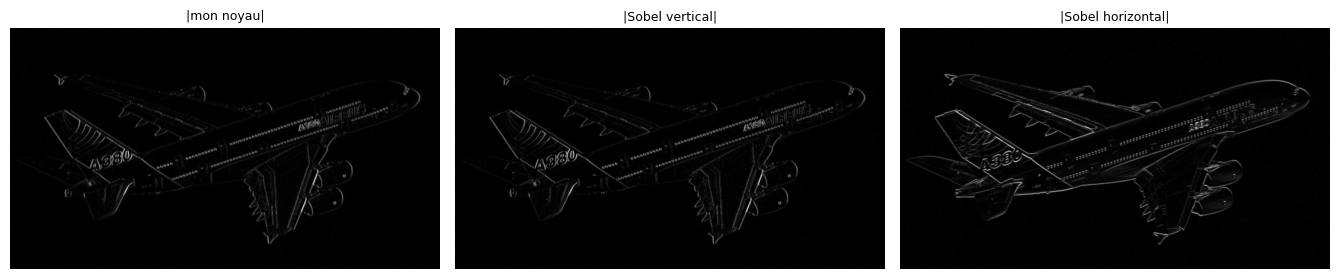

In [7]:
# Écrivez votre noyau 3×3 (celui annoncé dans R1), puis appliquez-le avec conv2d_naive, ainsi que SOBEL_V et SOBEL_H.
mon_noyau = np.array([[-5, 0, 5],
                      [-5, 0, 5],
                      [-5, 0, 5]], np.float32)
print('mon noyau :\n', mon_noyau, '\nsomme des coefficients :', mon_noyau.sum())
out_mien = conv2d_naive(gray, mon_noyau)
out_v = conv2d_naive(gray, SOBEL_V)
out_h = conv2d_naive(gray, SOBEL_H)
print('entrée', gray.shape, '→ sortie', out_v.shape)
show_grid([np.abs(out_mien), np.abs(out_v), np.abs(out_h)],
          ['|mon noyau|', '|Sobel vertical|', '|Sobel horizontal|'], ncols=3, size=4.5, cmap='gray')

In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""mon_noyau = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]], np.float32)       # exemple : différence gauche/droite (Prewitt)
out_mien = conv2d_naive(gray, mon_noyau)
out_v = conv2d_naive(gray, SOBEL_V)
out_h = conv2d_naive(gray, SOBEL_H)""")

---
### ✍️ Réponse R1 (suite) — 0 pt

> **Observation / explication.**
> - Comparez la sortie de votre noyau et celle de Sobel vertical : qu'est-ce qui ressort, qu'est-ce qui ne ressort pas ? Votre prédiction tenait-elle ?
> - Pourquoi le ciel est-il presque **uniformément nul** dans les trois sorties ?
> - Quelle est la taille de la sortie par rapport à l'entrée ? Expliquez la différence.

Les démarquations verticales sont nettes sur mon noyau et celui de Sobel vertical, en revanche les zones horizontales sont très faiblement voir pas du tout détectées.
Le ciel est uniformément nul sur chacun des noyaux car ces noyaux sont conçus pour repérer une différence de teintes entre pixels voisins, or les pixels composants le ciel sont presque tous exactement de la même teinte.
La taille de la sortie dépend de la taille du noyau. Un noyau doit être de dimension impair. Pour une entrée de dimension 100x100, la sortie d'une convolution par un noyau 3x3 sera de taille 98x98, par un noyau 5x5 sera de taille 96x96, par un noyau 7x7 sera de taille 94x94 etc.

### 1.6 ✏️ La même chose avec PyTorch, puis stride et padding

<center>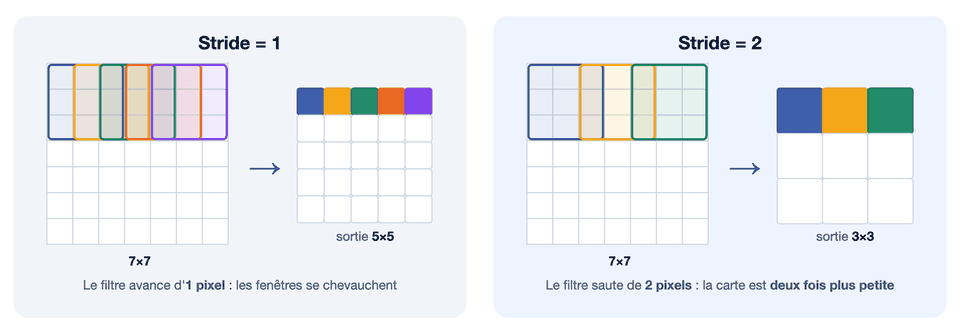<br>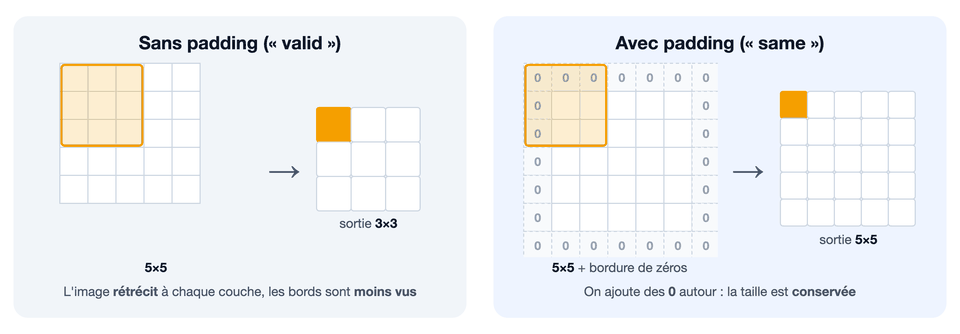</center>

Dans un réseau, on n'écrit pas de boucles : on appelle `F.conv2d`, le même calcul en code optimisé. Deux réglages changent la taille de la sortie : le **stride** (pas du noyau) et le **padding** (bordure de zéros). Pour une entrée de hauteur $H$, un noyau $k \times k$, un padding $p$ et un stride $s$ :

$$H_{out} = \left\lfloor \frac{H + 2p - k}{s} \right\rfloor + 1$$

> ✏️ **À compléter.**
> 1. Vérifiez que `F.conv2d` donne la même sortie que `conv2d_naive` (avec `np.allclose`).
> 2. Pour quatre réglages `(stride, padding)`, comparez la taille prédite par la formule et la taille obtenue.

> 👀 **À regarder** : les quatre lignes doivent afficher ✓. Si l'une affiche ✗, c'est votre formule qu'il faut revoir.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>F.conv2d</code> attend une entrée de forme <code>(B, C_in, H, W)</code> (B = nombre d'images, C_in = canaux) et un noyau <code>(C_out, C_in, k, k)</code>. Les deux <code>[None, None]</code> ajoutent ces dimensions : l'image grise devient <code>(1, 1, 428, 761)</code>.</li>
<li>Dans une couche <code>nn.Conv2d</code>, les noyaux ne sont pas écrits à la main comme Sobel : ils sont <b>appris</b> par descente de gradient. C'est la différence entre traitement d'image classique et CNN.</li>
<li><code>np.allclose</code> compare avec une tolérance, car les deux calculs n'arrondissent pas exactement pareil.</li>
<li>Ce que PyTorch appelle convolution est une corrélation croisée (noyau non retourné), comme <code>conv2d_naive</code>. Pour un noyau appris, cela ne change rien.</li>
</ul>
📖 <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html">F.conv2d</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html">nn.Conv2d</a> (section <i>Shape</i> : la formule de taille) · <a href="https://numpy.org/doc/stable/reference/generated/numpy.allclose.html">numpy.allclose</a>
</details>

In [8]:
x = torch.tensor(gray)[None, None]           # (1,1,H,W)
k = torch.tensor(SOBEL_V)[None, None]        # (1,1,3,3)

y_torch = F.conv2d(x, k)[0, 0]                     # (1,1,Hout,Wout) → (Hout,Wout)
same = torch.allclose(y_torch, torch.tensor(out_v), atol=1e-3)
print('F.conv2d identique à conv2d_naive :', same)

H, W = gray.shape
ks = k.shape[-1]                                   # taille du noyau (3)
for s, p in [(1, 0), (2, 0), (1, 1), (2, 1)]:
    pred = ((H + 2 * p - ks) // s + 1, (W + 2 * p - ks) // s + 1)
    got = tuple(F.conv2d(x, k, stride=s, padding=p).shape[-2:])
    print(f'stride={s} padding={p} : formule {pred}  obtenu {got}  {"✓" if pred == got else "✗"}')



F.conv2d identique à conv2d_naive : True
stride=1 padding=0 : formule (426, 759)  obtenu (426, 759)  ✓
stride=2 padding=0 : formule (213, 380)  obtenu (213, 380)  ✓
stride=1 padding=1 : formule (428, 761)  obtenu (428, 761)  ✓
stride=2 padding=1 : formule (214, 381)  obtenu (214, 381)  ✓


In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""y_torch = F.conv2d(x, k)[0, 0].numpy()
print('identique à la version NumPy :', np.allclose(y_torch, out_v, atol=1e-3))

H, W = gray.shape
for s, p in [(1, 0), (2, 0), (1, 1), (2, 1)]:
    pred = ((H + 2 * p - 3) // s + 1, (W + 2 * p - 3) // s + 1)
    got = tuple(F.conv2d(x, k, stride=s, padding=p).shape[-2:])
    print(f'stride={s} padding={p} : formule {pred}  obtenu {got}  {"✓" if pred == got else "✗"}')""")

---
### ✍️ Réponse R2 — 1 pt

> Un filtre 3×3 a **9 poids**, quelle que soit la taille de l'image.
> - Combien de poids aurait une couche **dense** qui relie chaque pixel de cette image en niveaux de gris (428×761) à une sortie de la même taille ? (Ordre de grandeur suffit.)
> - Si l'image est deux fois plus grande dans chaque dimension, que deviennent ces deux nombres ?
> - En une phrase : qu'est-ce que cela dit sur ce que la convolution « suppose » à propos des images ?

Le nombre de poids d'une couche dense correspond au nombre d'entrée fois le nombre de sortie. Ici on considère une sortie de même dimension que l'entrée soit (428*761)^2 poids, soit environ 100 milliards de poids.

---
## Bloc 2 — Que voit chaque couche ? (35 min)

Au bloc 1, vous avez appliqué **un** noyau écrit à la main. Un vrai CNN en empile des milliers, appris automatiquement. On ouvre un réseau réel et on regarde ce qui sort de chaque étage.

### 2.1 🔧 ResNet-50, un réseau déjà entraîné

<center>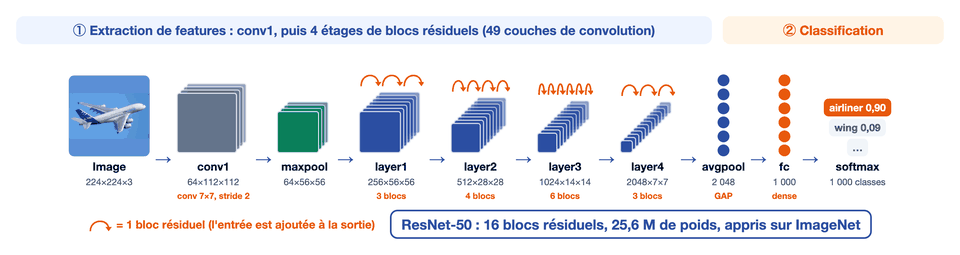</center>

**ResNet-50** a 50 couches et 25,6 millions de poids, déjà appris sur 1,28 million de photos **ImageNet** réparties en 1 000 classes, dont `airliner`. Il enchaîne une première convolution, puis **4 étages de blocs résiduels** (les arcs orange) : chaque bloc ajoute une correction à son entrée au lieu de la remplacer, ce qui permet d'empiler autant de couches. Les cartes rétrécissent (224 → 7 pixels) et se multiplient (3 → 2 048 canaux) ; un GAP et une couche dense donnent les 1 000 scores.

On ne l'entraîne pas : on lui montre l'A380 et on lit ses 5 réponses les plus probables.

> ⚠️ **Attention** · `.eval()` est obligatoire avant de prédire. Sans lui, la batch norm se comporte comme à l'entraînement et fausse le résultat.

> 👀 **À regarder** : la probabilité de `airliner`, et les quatre classes suivantes. Qu'ont-elles en commun avec un avion de ligne ?

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>ResNet50_Weights.IMAGENET1K_V1</code> désigne un jeu de poids ; <code>weights.meta['categories']</code> donne les noms des 1 000 classes.</li>
<li><code>resnet50(weights=...)</code> construit le réseau et télécharge les poids (environ 100 Mo, au premier appel seulement).</li>
<li><code>p.requires_grad_(False)</code> : on ne calculera pas de gradient pour ces poids, puisqu'on ne les modifie pas. Économie de mémoire.</li>
<li>Le réseau renvoie 1 000 <b>scores bruts</b> (logits). <code>softmax(1)</code> les transforme en probabilités qui somment à 1 (dimension 1 = les classes). <code>topk(5)</code> garde les 5 plus grandes.</li>
<li><code>@torch.no_grad()</code> désactive le suivi des gradients dans la fonction : plus rapide.</li>
</ul>
📖 <a href="https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html">resnet50</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.eval">Module.eval</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.no_grad.html">torch.no_grad</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.softmax.html">softmax</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.topk.html">topk</a> · article : <a href="https://arxiv.org/abs/1512.03385">He et al., 2015</a>
</details>

In [9]:
weights = ResNet50_Weights.IMAGENET1K_V1
resnet = resnet50(weights=weights).eval().to(DEVICE)
CATS = weights.meta['categories']
for p in resnet.parameters(): p.requires_grad_(False)

@torch.no_grad()
def top5(model, img, cats=CATS):
    probs = model(to_input(img).to(DEVICE)).softmax(1)[0].cpu()
    v, i = probs.topk(5)
    return [(cats[j], round(float(p), 3)) for p, j in zip(v, i)]

for name, p in top5(resnet, A380): print(f'{p:6.3f}  {name}')

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 192MB/s]


 0.900  airliner
 0.086  wing
 0.007  space shuttle
 0.006  warplane
 0.001  projectile


### 2.2 🔧 Anatomie : couches, tailles de sortie, nombre de paramètres

| Étage | Contenu | Sortie (C × H × W) |
|---|---|---|
| `conv1` → `maxpool` | conv 7×7 stride 2, puis max pooling | 64 × 56 × 56 |
| `layer1` → `layer4` | 3, 4, 6 et 3 blocs résiduels | 256 × 56 × 56 → 2048 × 7 × 7 |
| `avgpool` | moyenne de chaque carte (GAP) | 2048 |
| `fc` | couche dense | 1000 scores |

Pour voir ce qui sort de chaque étage, on accroche à chaque couche un **hook** : une fonction appelée automatiquement après son calcul, qui range la sortie dans le dictionnaire `acts`. Après un passage de l'A380, `acts['layer2']` contient les cartes de `layer2`.

> 👀 **À regarder** : en montant dans le réseau, comment évoluent la taille H × W et le nombre de canaux C ? Dans quelle couche sont la plupart des paramètres ?

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Un bloc résiduel de ResNet-50 (« bottleneck ») enchaîne une conv 1×1 qui réduit les canaux, une conv 3×3, une conv 1×1 qui les ré-augmente, puis ajoute l'entrée.</li>
<li><code>register_forward_hook(f)</code> : PyTorch appellera <code>f(module, entrée, sortie)</code> à chaque passage dans la couche.</li>
<li><code>module.parameters()</code> donne les tenseurs de poids, <code>p.numel()</code> leur nombre de valeurs. Pour une convolution sans biais : <code>k × k × C_in × C_out</code> poids.</li>
</ul>
📖 <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook">register_forward_hook</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.parameters">Module.parameters</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html">BatchNorm2d</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html">MaxPool2d</a>
</details>

In [10]:
STAGES = ['conv1', 'bn1', 'relu', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4', 'avgpool', 'fc']
acts = {}
def make_hook(name):
    def hook(m, inp, out): acts[name] = out.detach()
    return hook
handles = [getattr(resnet, n).register_forward_hook(make_hook(n)) for n in STAGES]

with torch.no_grad(): resnet(to_input(A380).to(DEVICE))

total = sum(p.numel() for p in resnet.parameters())
print(f"{'couche':8s} {'sortie (C,H,W)':>18s} {'paramètres':>12s} {'%':>6s}")
for n in STAGES:
    npar = sum(p.numel() for p in getattr(resnet, n).parameters())
    print(f'{n:8s} {str(tuple(acts[n].shape[1:])):>18s} {npar:12,d} {100*npar/total:5.1f}%')
print(f'{"total":8s} {"":>18s} {total:12,d}')

couche       sortie (C,H,W)   paramètres      %
conv1        (64, 112, 112)        9,408   0.0%
bn1          (64, 112, 112)          128   0.0%
relu         (64, 112, 112)            0   0.0%
maxpool        (64, 56, 56)            0   0.0%
layer1        (256, 56, 56)      215,808   0.8%
layer2        (512, 28, 28)    1,219,584   4.8%
layer3       (1024, 14, 14)    7,098,368  27.8%
layer4         (2048, 7, 7)   14,964,736  58.6%
avgpool        (2048, 1, 1)            0   0.0%
fc                  (1000,)    2,049,000   8.0%
total                         25,557,032


---
### ✍️ Réponse R3 — 1.5 pts

> - Vérifiez **à la main** le nombre de paramètres de `conv1` (noyau 7×7, 3 canaux d'entrée, 64 de sortie, sans biais) et celui de la **première conv 3×3** de `layer1` (64 → 64, sans biais). Écrivez le calcul.
> - Où sont concentrés les paramètres du réseau : premières couches, dernières couches de convolution, couche dense ? Pourquoi, alors que les cartes de `layer4` sont minuscules (7×7) ?

Pour conv1 : Une couche de noyau à 7x7 = 49 poids, l'entrée à 3 couches donc 49*3 = 147 poids. Et on veut 64 cartes différentes en sortie. Donc 64*147 = 9 408 poids.
Pour layer 1 : 3x3x64x64 = 36 864 poids.
La taille des cartes n'intervient pas, en revenche le nombre de couche de l'entrée et de la sortie intervient deux fois, cela explique que les paramètres soient concentrés dans les dernières couches de convolution, là où il y a beaucoup de couches (2048 pour le layer4). Cela explique pourquoi le layer 4 à presque 15 millions de paramètres alors que les cartes sont très petites.

### 2.4 🔧 Les cartes de features, du bas vers le haut

Chaque carte est la réponse d'**un** filtre appris, à toutes les positions de l'image : jaune = motif présent, violet foncé = absent. C'est Sobel du bloc 1, mais avec des filtres choisis par le réseau. La cellule affiche les 16 premières cartes de 5 étages, calculées sur l'A380.

> ⚠️ **Attention** · Les couleurs sont normalisées carte par carte : comparez la répartition **dans** une carte, pas l'intensité entre deux cartes.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
📖 Pour aller plus loin : <a href="https://distill.pub/2017/feature-visualization/">Olah et al., <i>Feature Visualization</i>, Distill, 2017</a> (ce que « cherche » chaque neurone d'un réseau de vision, en images)
</details>

---
### ✍️ Réponse R4 — 2 pts

> **Prédiction, avant d'exécuter la cellule suivante.**
> - Qu'attendez-vous dans les cartes de `conv1` (première couche, noyaux 7×7 sur les pixels) ?
> - Et dans celles de `layer4` (dernière couche, 7×7 spatial, 2 048 canaux) ?

L'entrée est de dimensions 224x224 et le stride utilisé dans conv1 est de 2, la résolution est donc divisé par deux, on s'attend donc à des cartes de dimension 112x112. On devrait toujours être en mesure de deviner la silhouette de l'A380 sur des cartes variés (certaines devraient être similaire à de la détection de contour comme on a fait avec Sobel plus haut).
Pour la layer4, les cartes sont de dimensions 7x7, cela devrait être indéchiffrable pour nous car trop vague, peu de pixel donc peu de détails.

La carte conv1[7] est étrange, les zones lumineuses semblent être celles aux abords de changements "tranchants" dans l'image (bords d'attaque des ailes, turbine des réacteurs), on en déduit que cette carte est peu être utile pour localiser les zones complexes de l'images.

La carte layer4[13] est presque uniforme sauf en deux zones mesurant 1x2 pixels, on peut peu être imaginer que ces deux zones localisent les extrémités hautes et basses de l'objet sur l'image.


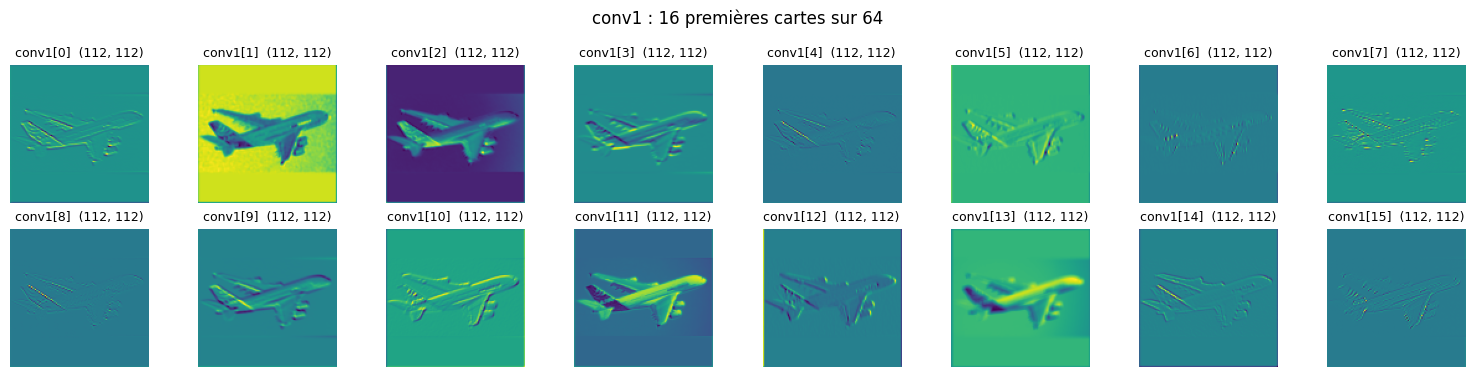

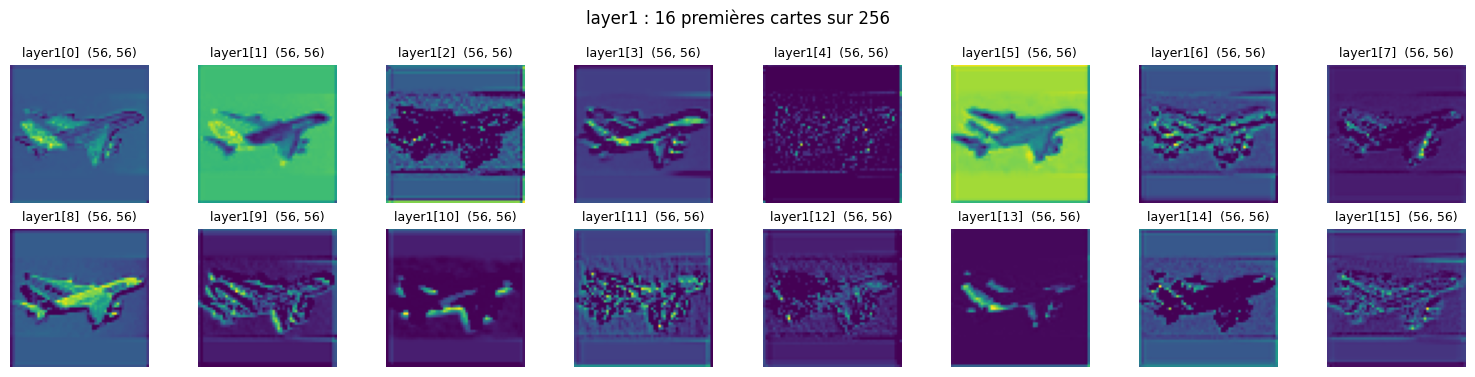

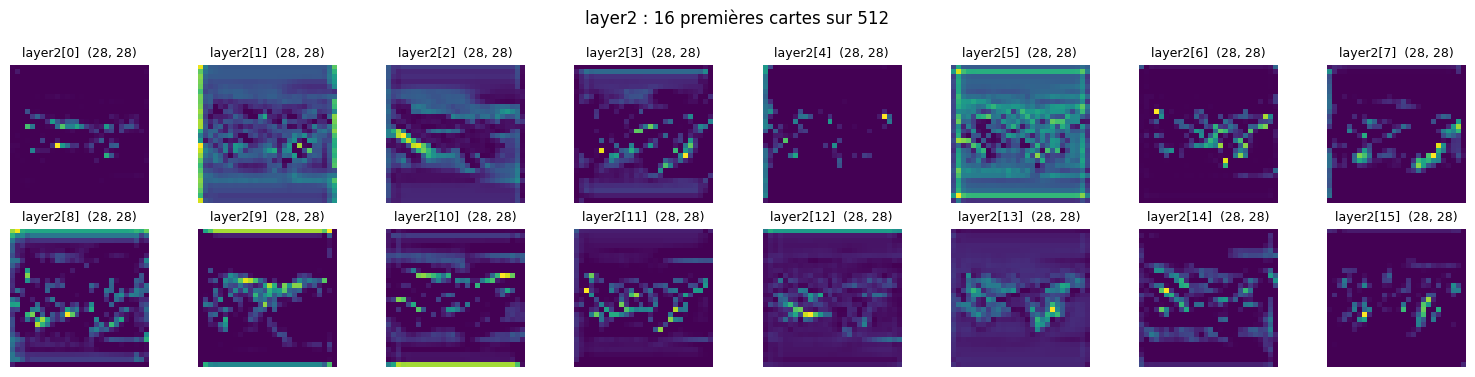

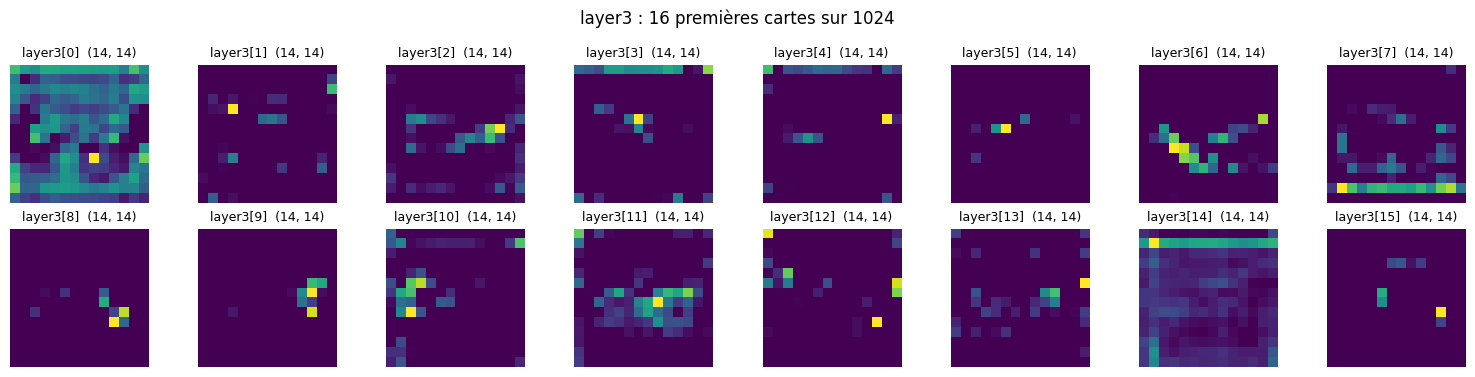

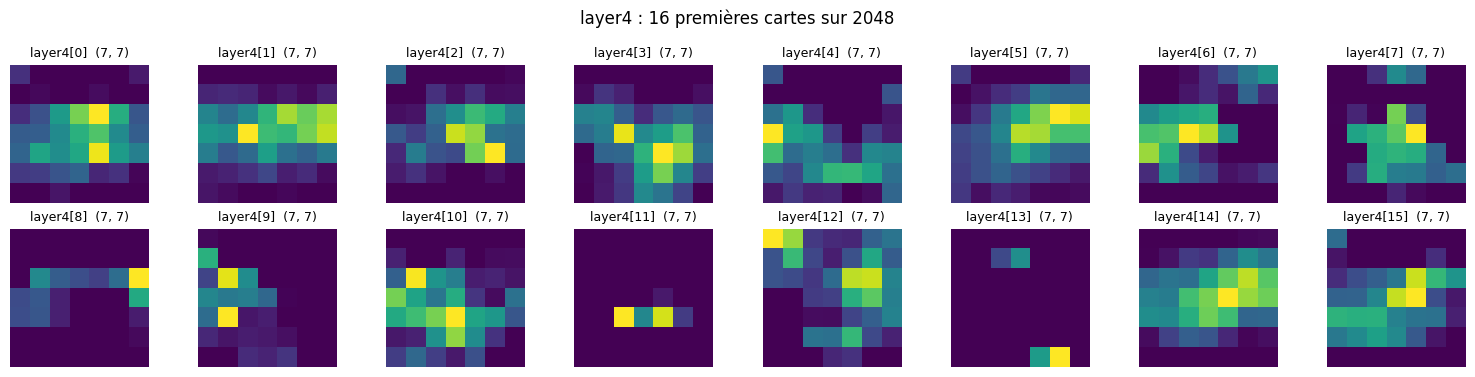

In [11]:
def maps(name, n=16):
    a = acts[name][0, :n].cpu()
    return [m.numpy() for m in a], [f'{name}[{i}]  {tuple(m.shape)}' for i, m in enumerate(a)]

for name in ['conv1', 'layer1', 'layer2', 'layer3', 'layer4']:
    ims, titles = maps(name)
    show_grid(ims, titles, ncols=8, size=1.9, cmap='viridis', suptitle=f'{name} : 16 premières cartes sur {acts[name].shape[1]}')

<center>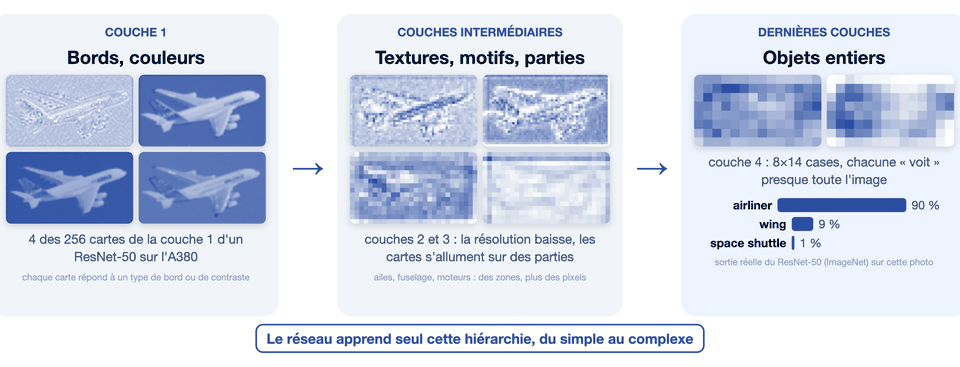</center>

Le cours annonçait cette hiérarchie : bords et couleurs en bas, parties d'objets au milieu, objets entiers en haut. Vos cartes la confirment-elles ?

**Observation (R4, suite).** Choisissez **une** carte de `conv1` et **une** carte de `layer4` qui vous intriguent. Notez leurs indices (le nombre entre crochets dans le titre) et décrivez dans R4 ce que chacune semble détecter : un bord ? une couleur ? le ciel ? une partie de l'avion ?

### 2.6 ✏️ Tester son hypothèse en modifiant l'image

Une description de carte n'est qu'une **hypothèse**. Pour la tester, on modifie l'image de façon contrôlée et on regarde si la carte réagit comme prévu.

| Variante | Ce qu'elle teste |
|---|---|
| miroir | la carte dépend-elle de l'orientation ? |
| couleurs inversées | des couleurs ou du contraste ? |
| flou fort | a-t-elle besoin de détails fins ? |
| avion masqué (à écrire) | répond-elle à l'avion ou au fond ? |

> ✏️ **À compléter** : la variante « avion masqué ». `a380_mask.png` est blanc sur l'avion. Comparé à 127, il donne un masque booléen `mask`, et `a[mask] = couleur` remplace d'un coup tous les pixels de l'avion. Mettez ensuite vos indices dans `CH1` et `CH4`.

> 👀 **À regarder** : pour chaque variante, votre carte change-t-elle de forme, de position, d'intensité ?

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Miroir : <code>A380.transpose(Image.FLIP_LEFT_RIGHT)</code>. Couleurs inversées : <code>255 - pixels</code>. Flou : <code>A380.filter(ImageFilter.GaussianBlur(6))</code>.</li>
<li>Partez d'une copie du tableau (<code>.copy()</code>), sinon vous modifiez l'image d'origine.</li>
</ul>
📖 <a href="https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.transpose">Image.transpose</a> · <a href="https://pillow.readthedocs.io/en/stable/reference/ImageFilter.html#PIL.ImageFilter.GaussianBlur">GaussianBlur</a> · <a href="https://numpy.org/doc/stable/user/basics.indexing.html#boolean-array-indexing">masques booléens NumPy</a>
</details>

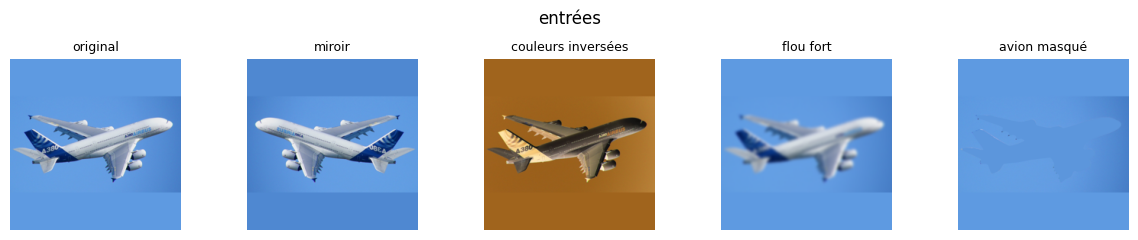

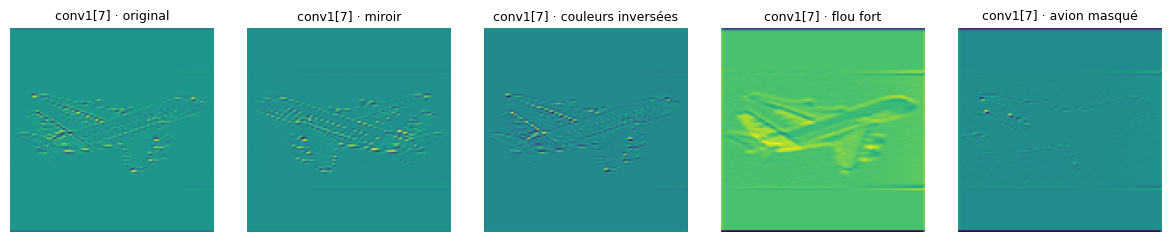

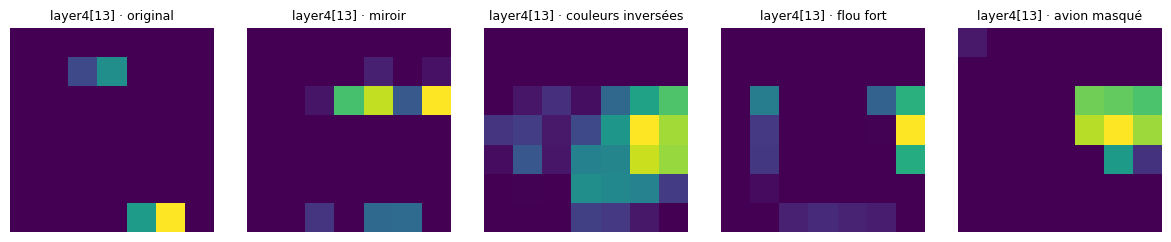

In [12]:
CH1 = 7    # indice de votre carte de conv1
CH4 = 13    # indice de votre carte de layer4

variantes = {
    'original': A380,
    'miroir': A380.transpose(Image.FLIP_LEFT_RIGHT),
    'couleurs inversées': Image.fromarray(255 - np.asarray(A380)),
    'flou fort': A380.filter(ImageFilter.GaussianBlur(6)),
}

# 5e variante : l'avion masqué, remplacé par la couleur moyenne du ciel
mask_img = Image.open(PHOTOS / 'a380_mask.png').convert('L')
if mask_img.size != A380.size:                                # sécurité si les tailles diffèrent
    mask_img = mask_img.resize(A380.size, Image.NEAREST)
mask = np.asarray(mask_img) > 127                             # True sur l'avion
a = np.asarray(A380.convert('RGB')).copy()                    # copie pour ne pas modifier l'original
ciel = a[~mask].mean(0).astype(np.uint8)                      # couleur moyenne de tout ce qui n'est pas l'avion
a[mask] = ciel
variantes['avion masqué'] = Image.fromarray(a)


rows = []
for nom, im in variantes.items():
    with torch.no_grad(): resnet(to_input(im).to(DEVICE))
    rows.append((nom, acts['conv1'][0, CH1].cpu().numpy(), acts['layer4'][0, CH4].cpu().numpy()))
show_grid([np.asarray(square_pad(im).resize((224, 224))) for im in variantes.values()], list(variantes), ncols=5, size=2.4, suptitle='entrées')
show_grid([r[1] for r in rows], [f'conv1[{CH1}] · {r[0]}' for r in rows], ncols=5, size=2.4, cmap='viridis')
show_grid([r[2] for r in rows], [f'layer4[{CH4}] · {r[0]}' for r in rows], ncols=5, size=2.4, cmap='viridis')

In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""mask = np.asarray(Image.open(PHOTOS / 'a380_mask.png').convert('L')) > 127
a = np.asarray(A380).copy(); a[mask] = a[:40, :200].reshape(-1, 3).mean(0).astype(np.uint8)
variantes['avion masqué'] = Image.fromarray(a)""")

---
### ✍️ Réponse R4 (suite) — 0 pt

> **Explication.**
> - Votre hypothèse sur chaque carte tient-elle face aux cinq variantes ? Qu'est-ce qui l'a confirmée ou démentie ?
> - Pourquoi les cartes de `layer4` sont-elles si **petites** (7×7) et si **nombreuses** (2 048), alors que celles de `conv1` sont grandes (112×112) et peu nombreuses (64) ?

Mon hypothèse pour la carte de conv1 semble s'avérer. Le flou fort "étale" les zones complexes. Tandis que sur la map avec l'avion masqué par la couleur moyenne du ciel, les zones les plus lumineuses se situe sur la partie gauche de l'image, là où la couleur du ciel est plus claire que sa couleure moyenne, et donc là où le ciel tranche avec la forme de l'avion. De plus l'avion semble être mal masqué sur quelques pixels, notamment sur le bord de fuite de l'aile gauche et on retrouve des points lumineux sur cette zone sur la map en sortie.

Pour le layer4, mon hypothèse semble être fausse, en effet, sur chaque variantes, les zones lumineuses ne correspondent pas aux extrémités haute et basse de l'avion. Je ne parviens pas à émettre une autre hypothèse qui pourrait être cohérente.

Les cartes layer4 sont petites et nombreuses car la détection de bords importe peu, ici le but est de repéré un motif, il y a beaucoup de potentiels motifs, donc beaucoup de cartes. Le stride de 2 appliqué plusieurs fois a permis à chaque pixel d'avoir une "vue" plus large de l'image de base" et a réduit la dimension. Pour les cartes de conv1, c'est l'inverse, les cartes sont grandes et peu nombreuses car le but est de détecter les bords et la forme générale de l'object, un nombre important de pixels est nécessaire pour contourer l'object.

### 2.8 ✏️ Mesurer un champ réceptif

<center>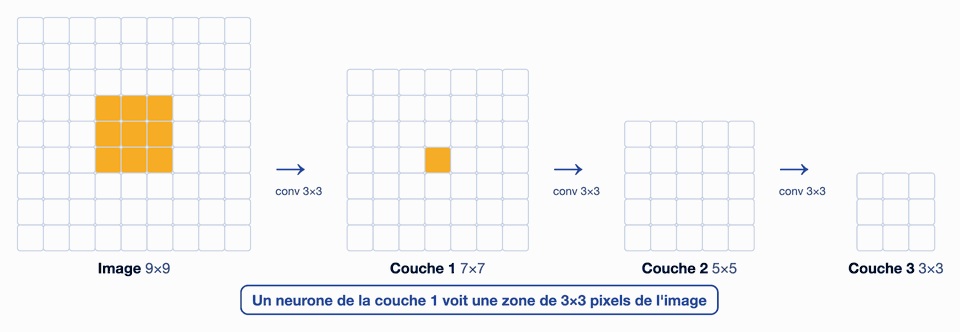</center>

Le **champ réceptif** d'un neurone est la zone de l'image qui peut influencer sa valeur. Chaque couche l'agrandit, et chaque stride accélère cette croissance.

> 🧪 **L'expérience.** On compare une image noire et la même avec **un seul pixel allumé** au centre. Dans la carte d'un étage, les cases qui changent sont celles qui « voient » ce pixel : leur étendue donne le champ réceptif.

> ✏️ **À compléter** : convertir la taille de la zone (en cases) en pixels d'entrée. La carte de `layer2` fait 28×28 pour 224 px d'entrée : une case vaut 224 / 28 = 8 px.

> 👀 **À regarder** : comment la zone grandit de `layer1` à `layer3`, comparée aux 224 px de l'image.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>np.where(diff > 1e-6)</code> renvoie les coordonnées des cases où la sortie a changé (le seuil ignore les erreurs d'arrondi).</li>
<li>La largeur de la zone vaut <code>max − min + 1</code> sur ces coordonnées.</li>
</ul>
📖 <a href="https://numpy.org/doc/stable/reference/generated/numpy.where.html">numpy.where</a> · <a href="https://distill.pub/2019/computing-receptive-fields/">Araujo et al., <i>Computing Receptive Fields</i>, Distill, 2019</a>
</details>

layer1: carte (56, 56), zone modifiée 9×9 cases ≈ 36×36 px d’entrée


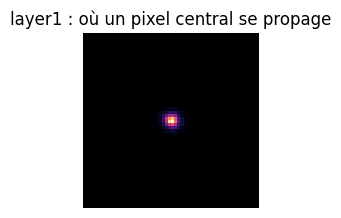

layer2: carte (28, 28), zone modifiée 11×11 cases ≈ 88×88 px d’entrée


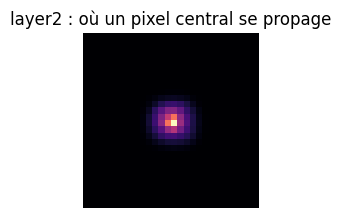

layer3: carte (14, 14), zone modifiée 14×14 cases ≈ 224×224 px d’entrée


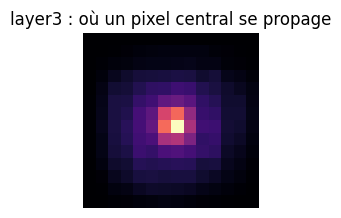

In [13]:
def receptive_field(stage):
    black = torch.zeros(1, 3, 224, 224); dot = black.clone(); dot[:, :, 112, 112] = 3.0
    with torch.no_grad():
        resnet(black.to(DEVICE)); a0 = acts[stage].clone()
        resnet(dot.to(DEVICE));   a1 = acts[stage].clone()
    diff = (a1 - a0).abs().sum(1)[0].cpu().numpy()          # carte (h,w) : où la sortie a changé
    ys, xs = np.where(diff > 1e-6)
    # Complétez : taille de la zone modifiée en cases de la carte, et conversion en pixels d'entrée
    # (la carte de layer2 fait 28×28 pour 224 px d'entrée : chaque case couvre 224/28 pixels).
    cells_h, cells_w = ys.max() - ys.min() + 1, xs.max() - xs.min() + 1
    # Conversion en pixels d'entrée : une case couvre 224 / (taille de la carte) pixels
    scale_h, scale_w = 224 / diff.shape[0], 224 / diff.shape[1]
    rf_px = (cells_h * scale_h, cells_w * scale_w)
    return diff, (cells_h, cells_w), rf_px

for stage in ['layer1', 'layer2', 'layer3']:
    diff, cells, rf = receptive_field(stage)
    print(f'{stage}: carte {diff.shape}, zone modifiée {cells[0]}×{cells[1]} cases ≈ {rf[0]:.0f}×{rf[1]:.0f} px d’entrée')
    show(diff, f'{stage} : où un pixel central se propage', size=3.5, cmap='magma')

In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""    cells_h, cells_w = ys.max() - ys.min() + 1, xs.max() - xs.min() + 1
    scale = 224 / diff.shape[0]
    rf_px = (cells_h * scale, cells_w * scale)""")

    cells_h, cells_w = ys.max() - ys.min() + 1, xs.max() - xs.min() + 1
    scale = 224 / diff.shape[0]
    rf_px = (cells_h * scale, cells_w * scale)


---
### ✍️ Réponse R5 — 1.5 pts

> - Quelle taille de champ réceptif (en pixels d'entrée) mesurez-vous à la sortie de `layer2` et de `layer3` ?
> - Dans le cours : « deux conv 3×3 empilées voient autant qu'une 5×5 ». Expliquez avec ce principe pourquoi le champ réceptif croît si vite alors que tous les noyaux font 3×3 ou 1×1.
> - Pourquoi un grand champ réceptif est-il indispensable pour reconnaître **un avion entier**, et pas seulement un morceau d'aile ?

8x8 en sortie de layer 2 et 12x10 en sortie de layer 3.
Le stride de 2 est responsable de la croissance rapide du champ réceptif. Après une convolution par un noyeau 3x3 et stride deux, une case de la map vaut 2x2 pixels de l'image, ainsi une conv 3x3 ajoute 4 pixels.
Un grand champ réceptif est indispensable car un neurone ne peut pas réagir à quelque chose qu'il ne voit pas.  

### 2.10 🎁 Bonus : votre photo

Déposez une photo d'avion dans le panneau *Fichiers* de Colab, nommez-la `ma_photo.jpg` et lancez la cellule. Choisissez-la **difficile** : vue de face, au sol, de nuit, très petite, militaire. Si `airliner` n'est pas premier, qu'est-ce qui l'emporte, et pourquoi selon vous ?

In [14]:
if Path('ma_photo.jpg').exists():
    mine = Image.open('ma_photo.jpg').convert('RGB'); show(mine, 'ma photo', size=4)
    for name, p in top5(resnet, mine): print(f'{p:6.3f}  {name}')
else:
    print('Pas de ma_photo.jpg : déposez une image pour faire ce bonus.')

Pas de ma_photo.jpg : déposez une image pour faire ce bonus.


---
## Bloc 3 — Pourquoi le transfer learning marche ? (40 min)

ResNet-50 a appris sur 1,28 million d'images. Pour un classifieur **avion / drone / oiseau** d'aéroport, vous aurez au mieux quelques centaines d'images annotées. Faut-il entraîner un réseau de zéro, ou réutiliser ce que ResNet sait déjà ? C'est le **transfer learning**. Vous allez comparer trois stratégies sur les mêmes données.

Le jeu `aero3` contient 300 photos par classe (licence CC0) : 240 pour l'**entraînement**, 60 pour la **validation**. Le modèle apprend sur le train ; on mesure sur la val, qu'il n'a jamais vue. Votre binôme n'utilise que `N_TRAIN` images par classe en train ; la val est la même pour tous.

### 3.1 🔧 Charger le jeu de données

<center>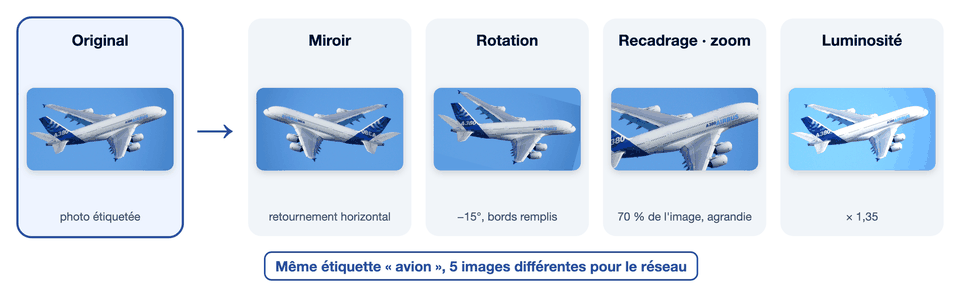</center>

À chaque epoch, chaque image d'entraînement est légèrement **modifiée au hasard** (recadrage, miroir) : c'est l'**augmentation de données**. Le réseau voit plus de variété, et sur-apprend moins. On n'augmente jamais la validation.

> 👀 **À regarder** : la grille d'exemples (déjà augmentés). Regardez aussi le **style** des photos de chaque classe : fond, distance, cadrage. Vous en aurez besoin au bloc 4.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>ImageFolder</code> lit un dossier rangé par classe (<code>train/avion/</code>, <code>train/drone/</code>…) ; classes numérotées par ordre alphabétique (avion = 0, drone = 1, oiseau = 2).</li>
<li><code>Subset</code> ne garde que <code>N_TRAIN</code> images par classe, tirées avec votre graine.</li>
<li><code>DataLoader</code> sert les images par paquets (<i>batches</i>) de 32, mélangés à chaque epoch, sous forme d'un tenseur <code>(32, 3, 224, 224)</code>.</li>
<li>Train : <code>RandomResizedCrop(224, scale=(0.7, 1.0))</code> (recadrage aléatoire de 70 à 100 % de l'image) et <code>RandomHorizontalFlip()</code>. Val : simple <code>Resize((224, 224))</code>. Les deux finissent par <code>ToTensor()</code> et <code>Normalize</code>.</li>
</ul>
📖 <a href="https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html">tutoriel Datasets & DataLoaders</a> · <a href="https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html">ImageFolder</a> · <a href="https://docs.pytorch.org/docs/stable/data.html">DataLoader et Subset</a> · <a href="https://docs.pytorch.org/vision/stable/transforms.html">transformations torchvision</a>
</details>

classes : ['avion', 'drone', 'oiseau'] | train : 120 images | val : 180


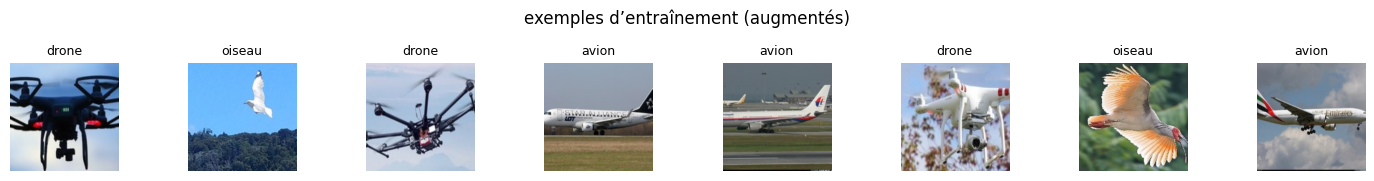

In [15]:
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset

tf_train = transforms.Compose([transforms.RandomResizedCrop(224, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip(),
                               transforms.ToTensor(), transforms.Normalize(IMNET_MEAN.flatten(), IMNET_STD.flatten())])
tf_val = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(IMNET_MEAN.flatten(), IMNET_STD.flatten())])

full_train = ImageFolder(AERO3 / 'train', tf_train)
val_ds = ImageFolder(AERO3 / 'val', tf_val)
CLASSES = full_train.classes
rng = np.random.RandomState(SEED)
idx = np.concatenate([rng.choice(np.where(np.array(full_train.targets) == c)[0], N_TRAIN, replace=False) for c in range(len(CLASSES))])
train_ds = Subset(full_train, idx)
NW = 2 if torch.cuda.is_available() else 0      # workers de chargement : 2 sur Colab GPU, 0 sur Mac/CPU
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=NW)
val_dl = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=NW)
print('classes :', CLASSES, '| train :', len(train_ds), 'images | val :', len(val_ds))

xb, yb = next(iter(train_dl))
show_grid([denorm(xb[i:i+1]) for i in range(8)], [CLASSES[int(y)] for y in yb[:8]], ncols=8, size=1.8, suptitle='exemples d’entraînement (augmentés)')

---
### ✍️ Réponse R6 — 3 pts

> **Prédiction, avant d'entraîner.** Vous allez entraîner trois modèles sur vos **N_TRAIN** images par classe :
>
> - **A. From scratch** : un petit CNN (3 couches de conv) initialisé au hasard, 10 epochs.
> - **B. Linear probe** : ResNet-50 ImageNet **gelé**, on n'entraîne que la couche dense finale (2048 → 3), 5 epochs.
> - **C. Fine-tuning** : ResNet-50 ImageNet **entièrement dégelé**, petit learning rate, 5 epochs.
>
> Pour chacun, prédisez en une phrase : la val accuracy approximative, et s'il va **sur-apprendre** (train ≫ val). Justifiez avec votre N_TRAIN.

J'ai N_TRAIN = 40 (120 images, donc 4 batches par epoch) :

A. From scratch : environ 50 % de val accuracy. Plutôt du sous-apprentissage que du sur-apprentissage car 40 pas de gradient seulement pour apprendre tous les filtres à partir de zéro semble peu.
B. Linear probe : environ 90 % d'accuracy, sans sur-apprentissage (train ≈ val). Car avions et oiseaux sont déjà séparés.
C. Fine-tuning : environ 90 à 95 %, léger sur-apprentissage (train proche de 100 %). 23,5 M de poids pour 120 images, mais le départ ImageNet et le petit learning rate limitent l'écart, et 20 pas suffisent à peine à dépasser B.

### 3.3 🔧 La boucle d'entraînement

<center>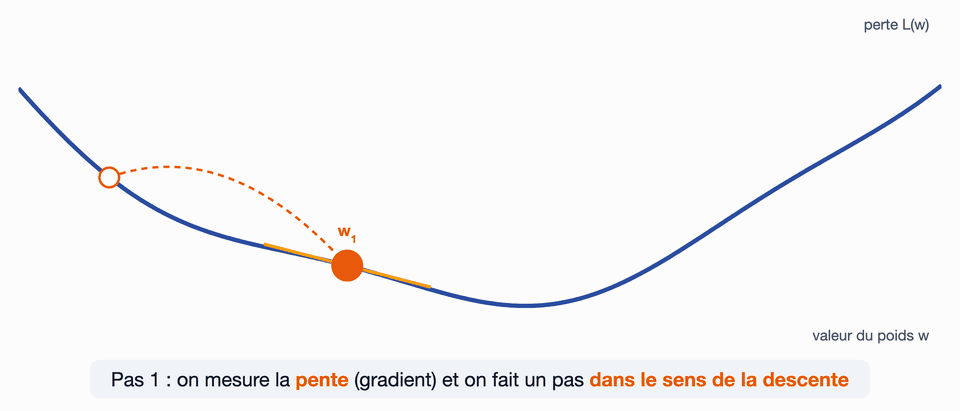</center>

Chaque **batch** d'images fait un pas de **descente de gradient** :
1. **passe avant** : le modèle donne ses scores ;
2. **perte** : la cross-entropy mesure l'écart avec les bonnes étiquettes ;
3. **rétropropagation** : `loss.backward()` calcule le gradient de la perte pour chaque poids ;
4. **mise à jour** : `opt.step()` déplace chaque poids pour faire baisser la perte.

Une **epoch** = un passage sur toutes les images d'entraînement. Après chaque epoch, on mesure la perte et l'**accuracy** (proportion d'images bien classées) sur la validation.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>opt.zero_grad()</code> remet les gradients à zéro avant chaque <code>backward()</code>, car PyTorch les additionne d'un appel à l'autre.</li>
<li><code>F.cross_entropy</code> applique elle-même le softmax : on lui donne les scores bruts.</li>
<li><b>Adam</b> est une descente de gradient qui adapte le pas de chaque poids ; son réglage principal est le <b>learning rate</b> <code>lr</code>. On ne lui passe que les poids qui ont <code>requires_grad=True</code> : c'est ce qui permettra de geler une partie du réseau.</li>
<li><code>model.train()</code> / <code>model.eval()</code> basculent la batch norm entre ses deux modes (voir 2.1).</li>
<li><code>train</code> renvoie un historique (pertes, accuracies, temps, nombre de poids entraînés) tracé en 3.7.</li>
</ul>
📖 <a href="https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html">tutoriel Optimizing Model Parameters</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html">cross_entropy</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html">Adam</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.Tensor.backward.html">Tensor.backward</a>
</details>

In [16]:
def evaluate(model, dl):
    model.eval(); loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(DEVICE), y.to(DEVICE); out = model(x)
            loss += F.cross_entropy(out, y, reduction='sum').item(); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return loss / n, correct / n

def train(model, epochs, lr, name):
    model.to(DEVICE); seed_all()
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); loss_sum, correct, n = 0.0, 0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x); loss = F.cross_entropy(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
        vl, va = evaluate(model, val_dl)
        for k, v in zip(hist, [loss_sum / n, correct / n, vl, va]): hist[k].append(v)
        print(f'{name} ep {ep+1:2d}/{epochs} | train loss {loss_sum/n:.3f} acc {correct/n:.3f} | val loss {vl:.3f} acc {va:.3f}')
    hist['time_s'] = round(time.time() - t0, 1); hist['n_trainable'] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'→ {hist["n_trainable"]:,} paramètres entraînés en {hist["time_s"]} s')
    return hist

HIST = {}

### 3.4 ✏️ Régime A : un petit CNN from scratch

<center>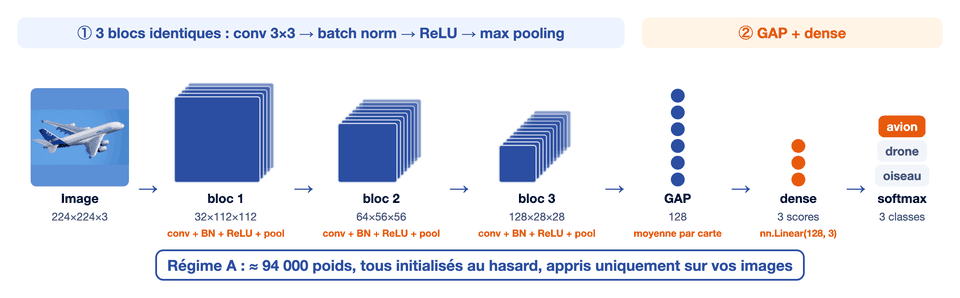</center>

**From scratch** : poids initialisés au hasard, le réseau n'apprend qu'avec vos `N_TRAIN × 3` images. Trois blocs *conv 3×3 → batch norm → ReLU → max pooling* réduisent l'image de 224×224 à 128 cartes de 28×28. Le **global average pooling** (GAP) fait la moyenne de chaque carte, puis une couche dense donne les 3 scores. Environ 94 000 poids, 250 fois moins que ResNet-50.

> ✏️ **À compléter** : la méthode `forward`, en trois lignes : `self.features`, puis la moyenne sur les dimensions spatiales (`x.mean(dim=(2, 3))`), puis `self.fc`.

> 👀 **À regarder** pendant l'entraînement : l'écart entre `train acc` et `val acc` au fil des epochs.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Un modèle PyTorch hérite de <code>nn.Module</code> : on <b>déclare</b> les couches dans <code>__init__</code>, on écrit le <b>calcul</b> dans <code>forward</code>. PyTorch en déduit seul la rétropropagation.</li>
<li><code>Conv2d(cin, cout, 3, padding=1)</code> garde la taille ; <code>MaxPool2d(2)</code> la divise par 2 : 224 → 112 → 56 → 28.</li>
<li>Dans <code>x.mean(dim=(2, 3))</code>, les dimensions 2 et 3 sont H et W : il reste <code>(B, 128)</code>.</li>
</ul>
📖 <a href="https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html">tutoriel Build the Neural Network</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html">nn.Module</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html">nn.Sequential</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html">nn.Linear</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.mean.html">torch.mean</a>
</details>

In [17]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        def block(cin, cout): return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.fc = nn.Linear(128, n_classes)
    def forward(self, x):
        # features -> global average pooling (moyenne sur H et W) -> fc
        x = self.features(x)        # (B, 128, 28, 28)
        x = x.mean(dim=(2, 3))      # global average pooling → (B, 128)
        return self.fc(x)           # (B, 3) : un score par classe

model_scratch = SmallCNN()
HIST['A_scratch'] = train(model_scratch, epochs=10, lr=1e-3, name='A scratch')

A scratch ep  1/10 | train loss 1.007 acc 0.525 | val loss 1.045 acc 0.467
A scratch ep  2/10 | train loss 0.857 acc 0.575 | val loss 0.988 acc 0.594
A scratch ep  3/10 | train loss 0.752 acc 0.758 | val loss 0.958 acc 0.578
A scratch ep  4/10 | train loss 0.690 acc 0.767 | val loss 0.962 acc 0.606
A scratch ep  5/10 | train loss 0.658 acc 0.808 | val loss 0.900 acc 0.611
A scratch ep  6/10 | train loss 0.612 acc 0.808 | val loss 0.855 acc 0.644
A scratch ep  7/10 | train loss 0.560 acc 0.775 | val loss 0.813 acc 0.667
A scratch ep  8/10 | train loss 0.557 acc 0.825 | val loss 0.795 acc 0.639
A scratch ep  9/10 | train loss 0.520 acc 0.817 | val loss 0.718 acc 0.678
A scratch ep 10/10 | train loss 0.498 acc 0.817 | val loss 0.737 acc 0.683
→ 94,083 paramètres entraînés en 11.7 s


In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""        x = self.features(x)             # (B,128,28,28)
        x = x.mean(dim=(2, 3))           # GAP -> (B,128)
        return self.fc(x)""")

### 3.5 ✏️ Régime B : linear probe (ResNet-50 gelé)

<center>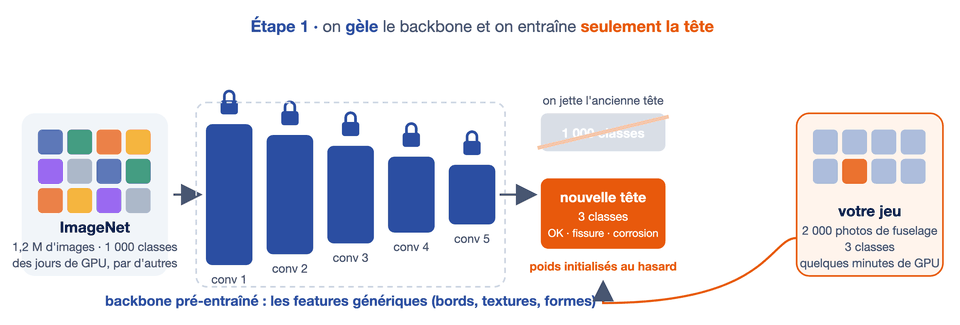</center>

Les 2 048 nombres qui sortent du GAP de ResNet-50 **décrivent** l'image : ce sont les *features* apprises sur ImageNet. Si cette description est bonne, une simple couche linéaire posée dessus suffit à séparer avion, drone et oiseau. On **gèle** tout ResNet (ses poids ne bougent plus) et on n'entraîne qu'une **nouvelle tête** de 2 048 × 3 + 3 = 6 147 poids.

> ✏️ **À compléter**, dans cet ordre : geler tous les paramètres (`requires_grad_(False)`), puis remplacer `fc` par `nn.Linear(2048, 3)`. Une couche neuve s'entraîne par défaut. Dans l'autre ordre, vous gèleriez aussi la nouvelle tête.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
📖 <a href="https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html">tutoriel PyTorch Transfer Learning</a> (les régimes B et C sur un autre jeu) · <a href="https://cs231n.github.io/transfer-learning/">CS231n, transfer learning</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.Tensor.requires_grad_.html">Tensor.requires_grad_</a>
</details>

In [18]:
model_probe = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
for p in model_probe.parameters():
    p.requires_grad_(False)                         # 1) on gèle tout ResNet
model_probe.fc = nn.Linear(2048, len(CLASSES))      # 2) nouvelle tête, entraînable par défaut
HIST['B_probe'] = train(model_probe, epochs=5, lr=1e-3, name='B probe  ')

B probe   ep  1/5 | train loss 1.060 acc 0.433 | val loss 0.635 acc 0.911
B probe   ep  2/5 | train loss 0.622 acc 0.892 | val loss 0.391 acc 0.967
B probe   ep  3/5 | train loss 0.360 acc 0.992 | val loss 0.263 acc 0.978
B probe   ep  4/5 | train loss 0.229 acc 1.000 | val loss 0.193 acc 0.978
B probe   ep  5/5 | train loss 0.162 acc 1.000 | val loss 0.163 acc 0.983
→ 6,147 paramètres entraînés en 8.5 s


In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""for p in model_probe.parameters(): p.requires_grad_(False)
model_probe.fc = nn.Linear(2048, len(CLASSES))          # nouvelle couche : requires_grad=True par défaut""")

### 3.6 ✏️ Régime C : fine-tuning complet

<center>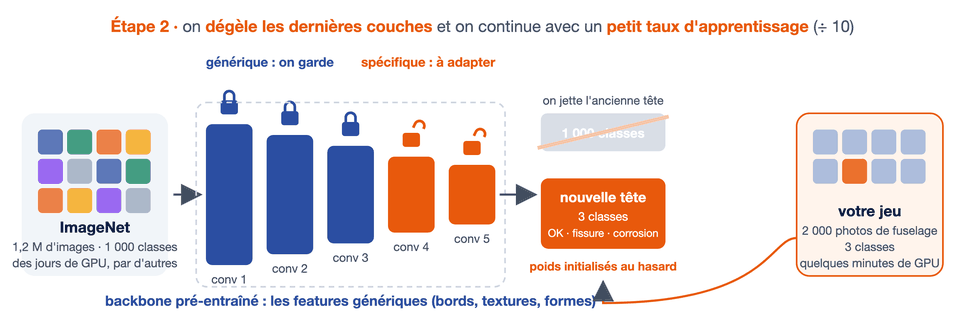</center>

Même départ que B, mais **tous** les poids s'entraînent (23,5 millions) : le réseau peut adapter ses features à la nouvelle tâche. Le learning rate est **10 fois plus petit** (`1e-4`) : les poids d'ImageNet sont déjà bons, de grands pas les détruiraient. On veut seulement les **affiner**.

> ✏️ **À compléter** : remplacer la tête, sans rien geler.

> 👀 **À regarder** : le temps d'entraînement comparé à B, et l'accuracy dès la première epoch.

In [19]:
model_ft = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
model_ft.fc = nn.Linear(2048, len(CLASSES))
HIST['C_finetune'] = train(model_ft, epochs=5, lr=1e-4, name='C finetune')

C finetune ep  1/5 | train loss 0.735 acc 0.758 | val loss 0.281 acc 0.983
C finetune ep  2/5 | train loss 0.127 acc 1.000 | val loss 0.076 acc 0.989
C finetune ep  3/5 | train loss 0.028 acc 1.000 | val loss 0.037 acc 0.978
C finetune ep  4/5 | train loss 0.007 acc 1.000 | val loss 0.028 acc 0.983
C finetune ep  5/5 | train loss 0.004 acc 1.000 | val loss 0.026 acc 0.983
→ 23,514,179 paramètres entraînés en 12.1 s


In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""model_ft.fc = nn.Linear(2048, len(CLASSES))""")

### 3.7 🔧 Les trois régimes côte à côte

<center>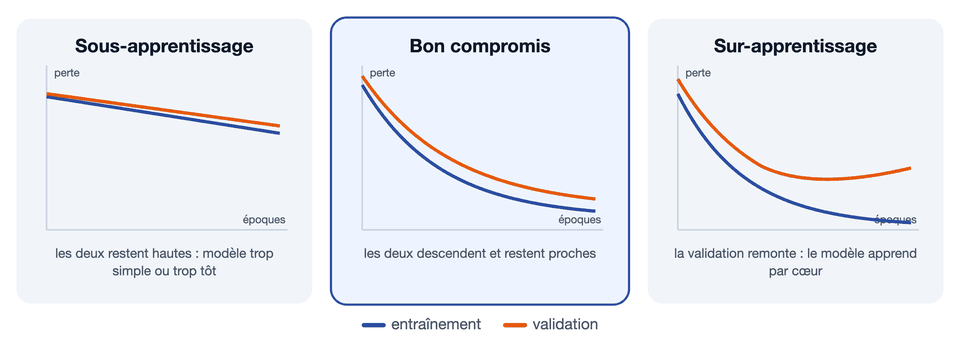</center>

Trait **plein = train**, **pointillé = val**, une couleur par régime. Quand la courbe train continue de s'améliorer pendant que la val stagne ou remonte, c'est du **sur-apprentissage**. Quand les deux restent médiocres, c'est du **sous-apprentissage**.

> 🛟 **Secours** : si l'entraînement est impossible (pas de GPU, manque de temps), la seconde cellule charge des courbes calculées à l'avance pour votre `N_TRAIN`, avec le même code. Dites-le dans R6.

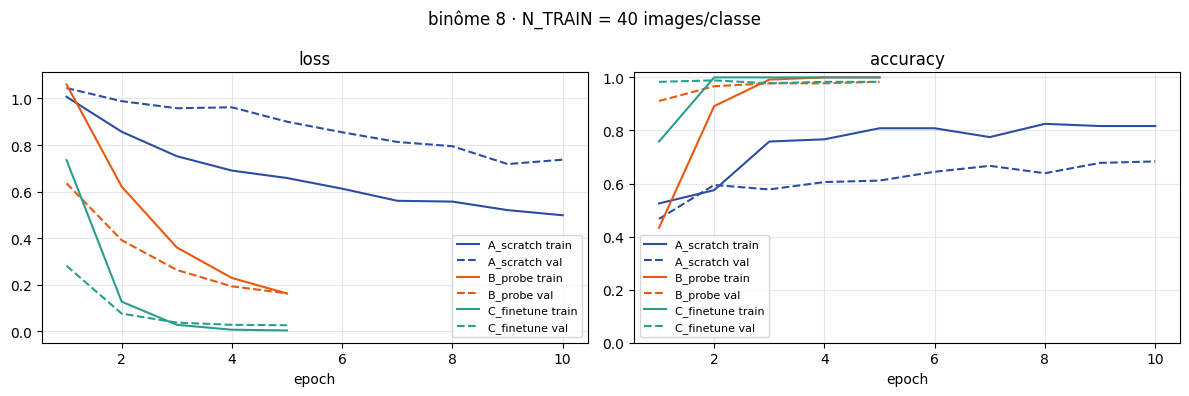

régime       val acc finale  train acc   paramètres entraînés    temps
A_scratch             0.683      0.817                 94,083      12s
B_probe               0.983      1.000                  6,147       8s
C_finetune            0.983      1.000             23,514,179      12s


In [20]:
def plot_hist(H, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for (name, h), col in zip(H.items(), ['#2b4ea2', '#e8590c', '#2a9d8f']):
        ep = range(1, len(h['train_loss']) + 1)
        axes[0].plot(ep, h['train_loss'], '-', color=col, label=f'{name} train'); axes[0].plot(ep, h['val_loss'], '--', color=col, label=f'{name} val')
        axes[1].plot(ep, h['train_acc'], '-', color=col, label=f'{name} train'); axes[1].plot(ep, h['val_acc'], '--', color=col, label=f'{name} val')
    axes[0].set_title('loss'); axes[1].set_title('accuracy'); axes[1].set_ylim(0, 1.02)
    for ax in axes: ax.set_xlabel('epoch'); ax.grid(alpha=.3); ax.legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()
    print(f"{'régime':12s} {'val acc finale':>14s} {'train acc':>10s} {'paramètres entraînés':>22s} {'temps':>8s}")
    for name, h in H.items():
        print(f"{name:12s} {h['val_acc'][-1]:14.3f} {h['train_acc'][-1]:10.3f} {h['n_trainable']:22,d} {h.get('time_s', float('nan')):7.0f}s")

plot_hist(HIST, f'binôme {BINOME} · N_TRAIN = {N_TRAIN} images/classe')

In [ ]:
#@title 🔧 Secours : courbes précalculées pour votre N_TRAIN (à n'utiliser que si l'entraînement est impossible)
SECOURS = json.load(open(DATA / 'curves' / f'curves_n{N_TRAIN}.json'))
plot_hist(SECOURS, f'courbes de secours · N_TRAIN = {N_TRAIN}')

---
### ✍️ Réponse R6 (suite) — 0 pt

> **Observation / explication.**
> - Confrontez vos courbes à vos prédictions. Lequel des trois régimes **sur-apprend** (train ≫ val, val loss qui remonte) ? Lequel apprend le plus vite ?
> - Combien de paramètres chaque régime entraîne-t-il ? Mettez ce nombre en regard de votre nombre d'images (N_TRAIN × 3).
> - Si vous aviez 4× plus de données, qu'est-ce qui changerait pour chaque régime ? (Comparez avec un binôme qui a un autre N_TRAIN.)

A sur-apprend : 81,7 % en train contre 68,3 % en val, et sa val loss stagne vers 0,73 alors que la train loss descend à 0,50. B et C ne sur-apprennent pas : 98,3 % en val, sans remontée de la val loss. C apprend le plus vite, avec 98 % en val dès l’epoch 1.
Paramètres pour 120 images : environ 94 000 pour A (≈ 780 par image), 6 147 pour B (≈ 50) et 23,5 M pour C (≈ 196 000). C a de loin le plus de poids par image sans sur-apprendre, grâce à son départ ImageNet et à son petit learning rate.
Avec 4 fois plus de données, A progresserait nettement (plus de pas de gradient, moins d’écart train/val). B et C, déjà à 98 %, gagneraient au mieux 1 point.

---
### ✍️ Réponse R7 — 1.5 pts

> Vous devez déployer un classifieur avion / drone / oiseau sur un site réel (caméra d'aéroport, par exemple), avec votre budget actuel de N_TRAIN images par classe.
> - Lequel des trois modèles choisissez-vous, et pourquoi (performance, risque de sur-apprentissage, coût) ?
> - Quelle **expérience** feriez-vous avant de trancher définitivement ? Décrivez-la concrètement (données, mesure, critère).

Je choisis B (linear probe). Il fait aussi bien que C (98,3 % en val, soit 3 erreurs sur 180 : l’écart entre les deux n’est pas mesurable), mais il n’entraîne que 6 147 poids pour 120 images. Le risque de sur-apprentissage est donc plus faible, et il est plus rapide à ré-entraîner. Une fois déployé, il coûte autant que C, puisque c’est un ResNet-50 dans les deux cas. A est écarté avec 68 %.

Avant de trancher, je testerais B et C sur des images de la vraie caméra : par exemple 100 par classe, prises sur plusieurs jours, par différentes météos et à différentes distances, jamais utilisées à l’entraînement. Notre val vient des mêmes sources que le train, elle surestime donc probablement la performance réelle. Je mesurerais l’accuracy et la matrice de confusion, en priorité le rappel sur la classe drone, car un drone pris pour un oiseau est l’erreur la plus grave.

<center>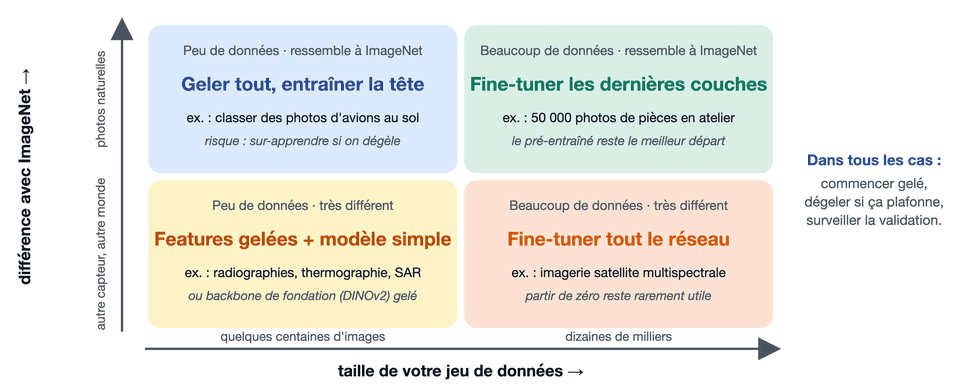</center>

Le cours résumait ainsi le choix de stratégie selon la taille et la nature des données. Comparez avec votre réponse R7.

### 3.10 🔧 Matrice de confusion et liste des erreurs

<center>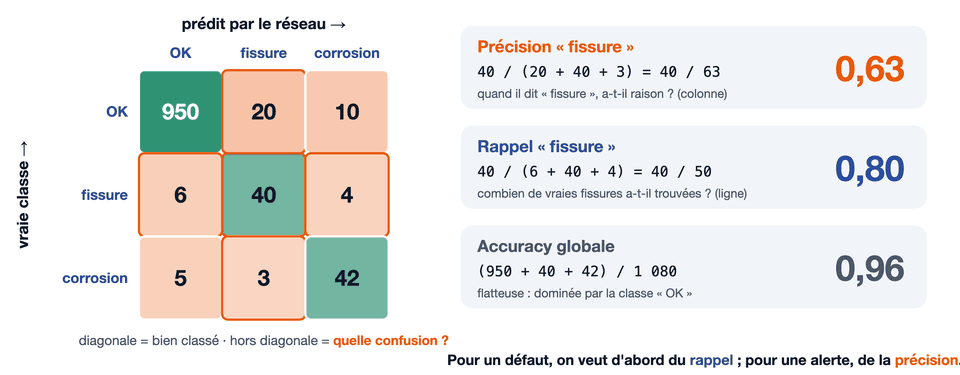</center>

Une accuracy ne dit pas **quelles** erreurs le modèle fait. Dans la **matrice de confusion**, ligne = vraie classe, colonne = classe prédite : la diagonale compte les bonnes réponses, tout le reste est une erreur. Toutes les erreurs n'ont pas le même coût : prendre un drone pour un oiseau sur un aéroport est plus grave que l'inverse.

La cellule calcule la matrice du modèle C, puis liste les erreurs de A et de C avec leur **confiance**. Une **erreur confiante** (le modèle se trompe en étant sûr de lui) révèle souvent ce qu'il a vraiment appris : on les étudie au bloc 4.

> 👀 **À regarder** : le nombre d'erreurs de C et celui de A. Gardez en tête que train et val viennent des mêmes sources.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>predict_all</code> renvoie les probabilités des 3 classes pour chaque image de val. <code>argmax(1)</code> donne la classe prédite, <code>max(1)</code> la confiance.</li>
<li><code>erreurs_de(model)</code> liste les images mal classées (vraie classe, prédite, confiance, chemin), de la plus confiante à la moins confiante.</li>
</ul>
📖 <a href="https://docs.pytorch.org/docs/stable/generated/torch.argmax.html">torch.argmax</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.max.html">torch.max</a> · <a href="https://scikit-learn.org/stable/modules/model_evaluation.html#confusion-matrix">matrice de confusion (scikit-learn)</a>
</details>

In [21]:
model_diag = model_ft if 'model_ft' in globals() else None
assert model_diag is not None, "Entraînez model_ft (3.6) ; sinon, le bloc 4 utilisera le ResNet ImageNet."

@torch.no_grad()
def predict_all(model, ds):
    model.eval(); P = []
    for x, y in DataLoader(ds, batch_size=64):
        P.append(model(x.to(DEVICE)).softmax(1).cpu())
    return torch.cat(P)

probs = predict_all(model_diag, val_ds); preds = probs.argmax(1).numpy(); conf = probs.max(1).values.numpy()
y_true = np.array(val_ds.targets)
cm = np.zeros((3, 3), int)
for t, p in zip(y_true, preds): cm[t, p] += 1
print('matrice de confusion (lignes = vrai, colonnes = prédit)\n', ' ' * 8 + '  '.join(f'{c:>7s}' for c in CLASSES))
for i, c in enumerate(CLASSES): print(f'{c:>8s}', '  '.join(f'{v:7d}' for v in cm[i]))
print(f'\naccuracy val : {(preds == y_true).mean():.3f}')

def erreurs_de(model):
    pr = predict_all(model, val_ds); pd, cf = pr.argmax(1).numpy(), pr.max(1).values.numpy()
    E = [dict(i=int(i), path=val_ds.samples[i][0], vrai=CLASSES[y_true[i]], predit=CLASSES[pd[i]], conf=float(cf[i])) for i in np.where(pd != y_true)[0]]
    return sorted(E, key=lambda e: -e['conf'])

ERREURS_C = erreurs_de(model_diag)
ERREURS_A = erreurs_de(model_scratch)
for nom, E in [('C fine-tuné', ERREURS_C), ('A from scratch', ERREURS_A)]:
    print(f'\n{nom} : {len(E)} erreurs sur {len(val_ds)}. Les plus confiantes :')
    for e in E[:5]: print(f"  vrai={e['vrai']:7s} prédit={e['predit']:7s} conf={e['conf']:.2f}  {Path(e['path']).name}")

matrice de confusion (lignes = vrai, colonnes = prédit)
           avion    drone   oiseau
   avion      60        0        0
   drone       1       58        1
  oiseau       0        1       59

accuracy val : 0.983

C fine-tuné : 3 erreurs sur 180. Les plus confiantes :
  vrai=drone   prédit=oiseau  conf=0.76  drone_0018.jpg
  vrai=drone   prédit=avion   conf=0.60  drone_0038.jpg
  vrai=oiseau  prédit=drone   conf=0.51  oiseau_0041.jpg

A from scratch : 57 erreurs sur 180. Les plus confiantes :
  vrai=oiseau  prédit=drone   conf=1.00  oiseau_0041.jpg
  vrai=oiseau  prédit=drone   conf=0.90  oiseau_0046.jpg
  vrai=oiseau  prédit=drone   conf=0.83  oiseau_0010.jpg
  vrai=oiseau  prédit=drone   conf=0.83  oiseau_0030.jpg
  vrai=drone   prédit=oiseau  conf=0.81  drone_0050.jpg


---
## Bloc 4 — Où regarde le réseau, et peut-on le tromper ? (40 min)

Un modèle à 99 % peut avoir raison **pour de mauvaises raisons** : reconnaître un avion grâce à la piste derrière, un oiseau grâce aux feuilles. Pour un système aéronautique, il faut savoir **sur quoi** il fonde sa décision. Trois outils du cours : Grad-CAM, l'occlusion et le patch adversarial.

### 4.1 🔧 Grad-CAM, écrit à la main

<center>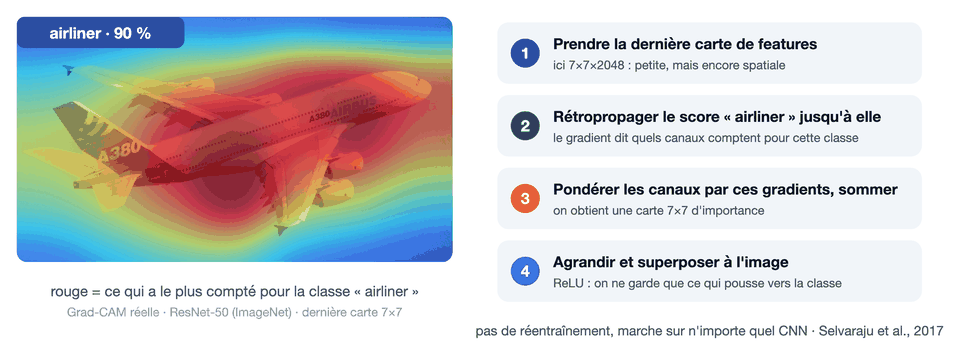</center>

La dernière couche de convolution produit des cartes 7×7 qui disent **où** chaque motif a été trouvé. Grad-CAM pondère chaque carte par son importance pour la classe (le gradient moyen du score), les additionne, et garde le positif. Résultat : une carte 7×7 agrandie et superposée à la photo, rouge = ce qui a le plus compté.

> ⚠️ **Attention** · Une case de 7×7 couvre 32 × 32 pixels : Grad-CAM dit « plutôt cette région », pas « ce pixel ».

> 👀 **À regarder** : sur l'A380, la zone rouge est-elle sur l'avion entier, une partie, le ciel ? Et sur les trois images de validation ?

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Un hook avant (comme en 2.2) récupère les cartes de <code>layer4</code> ; sur ces cartes, <code>register_hook</code> installe un crochet qui récupérera leur <b>gradient</b> pendant la rétropropagation.</li>
<li><code>out[0, class_idx].backward()</code> rétropropage le <b>score</b> de la classe (avant softmax), pas une perte.</li>
<li>Poids d'une carte = moyenne de son gradient sur les 7×7 cases ; carte finale = <code>ReLU(Σ poids × carte)</code>.</li>
<li>Il faut remettre <code>requires_grad=True</code> sur les poids du modèle pour que les gradients existent.</li>
<li><code>overlay</code> agrandit la carte, la colore (palette <code>jet</code>) et la mélange à la photo.</li>
</ul>
📖 article : <a href="https://arxiv.org/abs/1610.02391">Selvaraju et al., Grad-CAM, 2017</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.Tensor.register_hook.html">Tensor.register_hook</a> · pour vos projets : <a href="https://github.com/jacobgil/pytorch-grad-cam">pytorch-grad-cam</a>
</details>

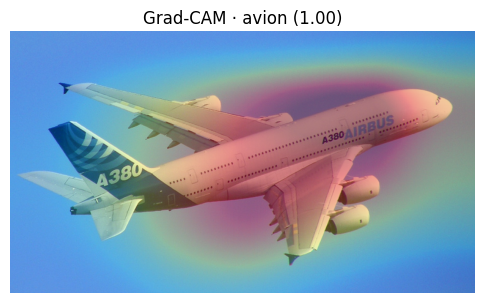

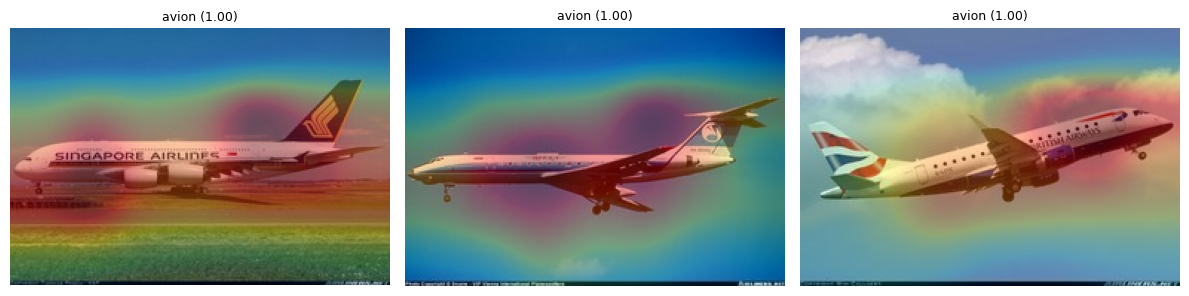

In [22]:
def gradcam(model, img_t, class_idx=None, layer=None):
    # img_t : (1,3,224,224) normalisé. Retourne (cam 7×7 normalisée 0..1, classe, proba).
    model.eval(); layer = layer or model.layer4
    store = {}
    def fwd_hook(m, i, o):
        store['a'] = o; o.register_hook(lambda g: store.__setitem__('g', g))   # gradient dL/d(cartes)
    h1 = layer.register_forward_hook(fwd_hook)
    out = model(img_t.to(DEVICE)); probs = out.softmax(1)[0]
    if class_idx is None: class_idx = int(probs.argmax())
    model.zero_grad(); out[0, class_idx].backward()
    h1.remove()
    w = store['g'].mean(dim=(2, 3), keepdim=True)                 # poids = gradient moyen par canal
    cam = F.relu((w * store['a']).sum(1))[0].detach().cpu().numpy()
    return cam / (cam.max() + 1e-8), class_idx, float(probs[class_idx].detach())

def overlay(img, cam, alpha=0.45):
    # Superpose la CAM (7×7) sur la photo complète (coordonnées du carré 224).
    sq = square_pad(img); S = sq.size[0]
    heat = np.asarray(Image.fromarray((cam * 255).astype(np.uint8)).resize((S, S), Image.BICUBIC)) / 255
    cmap = plt.get_cmap('jet')(heat)[..., :3]
    base = np.asarray(sq) / 255
    W, H = img.size; oy, ox = (S - H) // 2, (S - W) // 2
    mix = (1 - alpha * heat[..., None]) * base + alpha * heat[..., None] * cmap
    return (mix[oy:oy + H, ox:ox + W] * 255).astype(np.uint8)

# sur l'A380 avec le modèle fine-tuné (3 classes)
for p in model_diag.parameters(): p.requires_grad_(True)
cam, c, p = gradcam(model_diag, to_input(A380))
show(overlay(A380, cam), f'Grad-CAM · {CLASSES[c]} ({p:.2f})', size=6)

# sur 3 images de validation bien classées
ok = [i for i in range(len(val_ds)) if preds[i] == y_true[i]][:3]
ims, titles = [], []
for i in ok:
    im = Image.open(val_ds.samples[i][0]).convert('RGB'); cam, c, p = gradcam(model_diag, to_input(im))
    ims.append(overlay(im, cam)); titles.append(f'{CLASSES[c]} ({p:.2f})')
show_grid(ims, titles, ncols=3, size=4)

---
### ✍️ Réponse R8 — 1 pt

> Sur l'A380 : où regarde le réseau ? L'avion, le ciel, une partie précise ? Est-ce **rassurant** pour un usage réel ? Et sur les trois images de validation : le réseau regarde-t-il toujours l'objet ?

Sur l’A380 (« avion », 1,00), la zone rouge couvre le centre de l’avion : fuselage, emplanture des ailes et moteurs. Le ciel, les bouts d’ailes et la dérive restent froids. Sur les trois images de validation (« avion », 1,00), le réseau regarde aussi l’avion (fuselage, ailes, train), mais sur l’A380 au sol la chaleur déborde sur la piste. C’est plutôt rassurant

### 4.3 ✏️ Grad-CAM sur les erreurs confiantes de votre classe cible

<center>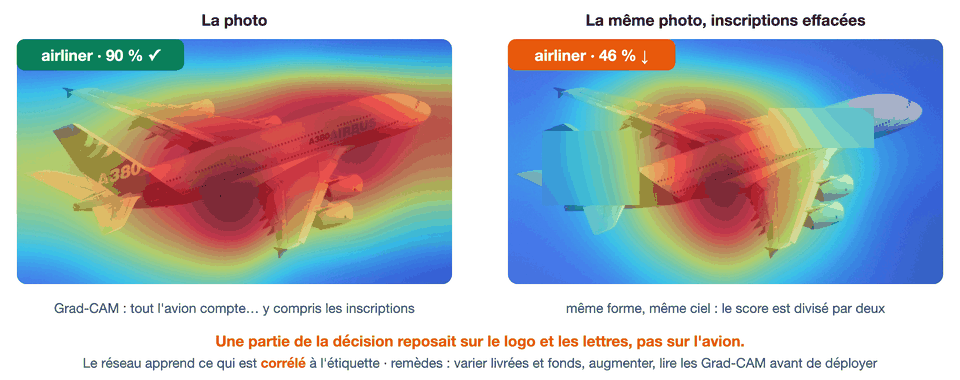</center>

Exemple du cours : sur l'A380, une partie de la décision reposait sur le logo et les lettres, pas sur l'avion. Un réseau apprend ce qui est **corrélé** à l'étiquette, pas forcément l'objet.

Le modèle C ne s'est presque jamais trompé ; le modèle A, souvent. On regarde ses **erreurs confiantes** sur votre `CLASSE_CIBLE` : pour chaque image, la photo, la Grad-CAM de A, et celle de C sur la même image.

> ✏️ **À compléter** : la sélection. Parmi `ERREURS_A`, gardez celles dont la **vraie** classe est `CLASSE_CIBLE` et la confiance > 0,8 ; si la liste est vide, abaissez à 0,5, puis prenez tout. Chaque erreur est un dictionnaire (`'vrai'`, `'predit'`, `'conf'`, `'path'`) : une compréhension de liste avec un `if` suffit.

> 👀 **Pour R9** : ouvrez `data/aero3/train/` dans le panneau *Fichiers* et regardez une vingtaine d'images de chaque classe. Les trois classes viennent de trois sources différentes. Le fond, la distance ou le cadrage suffiraient-ils à deviner la classe ?

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Pour A, la Grad-CAM est prise sur <code>model_scratch.features</code> (28×28), plus fine que celle de ResNet (7×7).</li>
</ul>
📖 <a href="https://docs.python.org/fr/3/tutorial/datastructures.html#list-comprehensions">compréhensions de liste</a>
</details>

4 erreur(s) retenue(s) · classe cible = oiseau


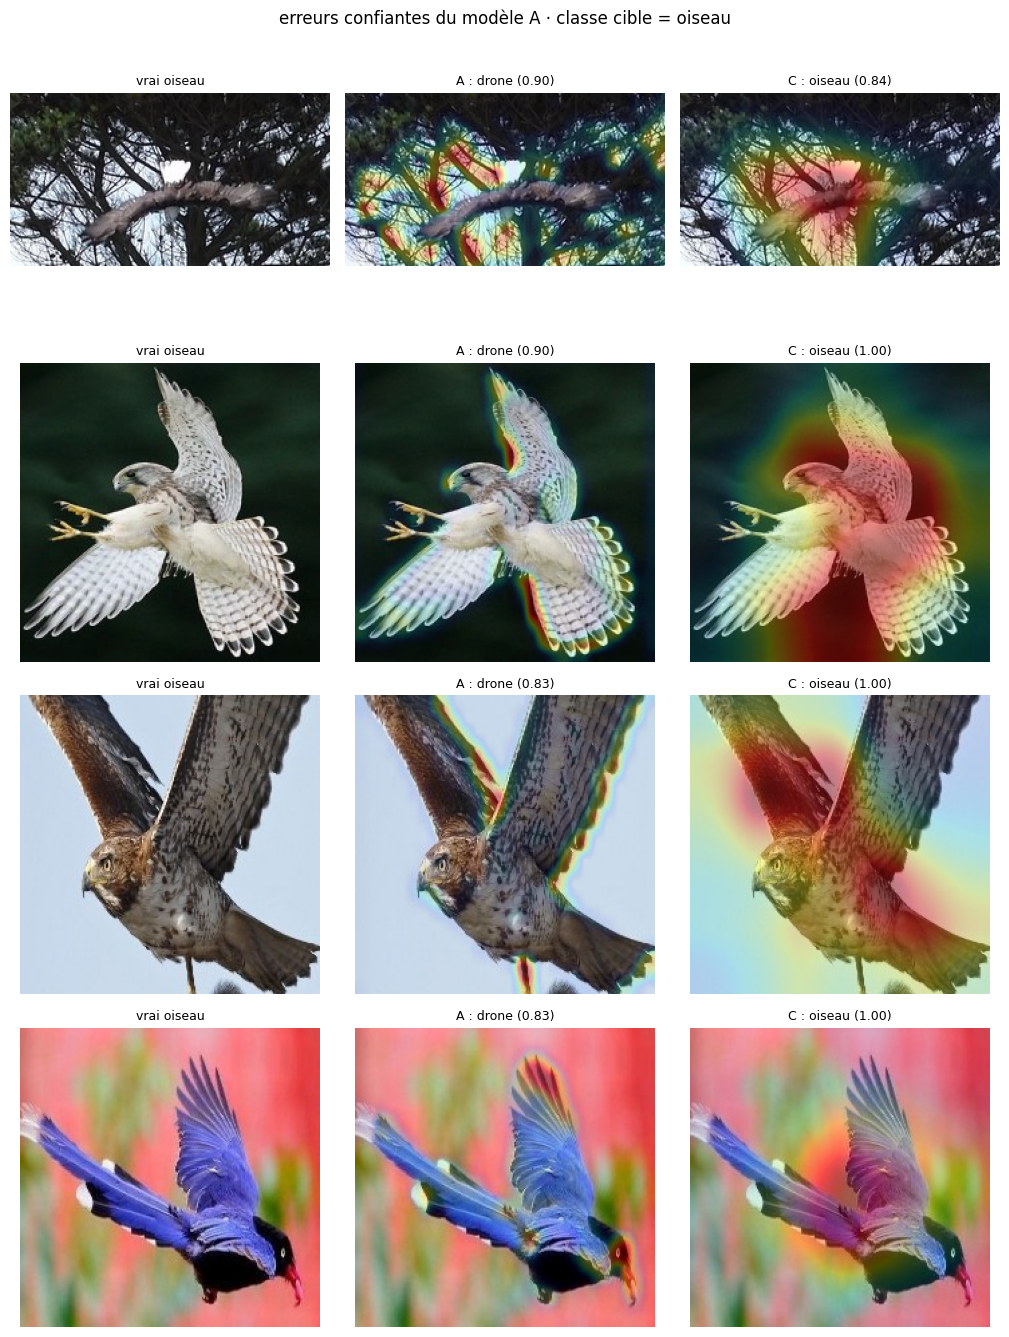

In [23]:
sel = [e for e in ERREURS_A if e['vrai'] == CLASSE_CIBLE and e['conf'] > 0.8]
if not sel:
    sel = [e for e in ERREURS_A if e['vrai'] == CLASSE_CIBLE and e['conf'] > 0.5]
if not sel:
    sel = [e for e in ERREURS_A if e['vrai'] == CLASSE_CIBLE]
if not sel:
    sel = ERREURS_A
print(f"{len(sel)} erreur(s) retenue(s) · classe cible = {CLASSE_CIBLE}")
sel = sel[:4]
for p in model_scratch.parameters(): p.requires_grad_(True)
ims, titles = [], []
for e in sel:
    im = Image.open(e['path']).convert('RGB')
    camA, cA, pA = gradcam(model_scratch, to_input(im), layer=model_scratch.features)
    camC, cC, pC = gradcam(model_diag, to_input(im))
    ims += [np.asarray(im), overlay(im, camA), overlay(im, camC)]
    titles += [f"vrai {e['vrai']}", f"A : {CLASSES[cA]} ({pA:.2f})", f"C : {CLASSES[cC]} ({pC:.2f})"]
show_grid(ims, titles, ncols=3, size=3.4, suptitle=f'erreurs confiantes du modèle A · classe cible = {CLASSE_CIBLE}')

In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""sel = [e for e in ERREURS_A if e['vrai'] == CLASSE_CIBLE and e['conf'] > 0.8]
if not sel: sel = [e for e in ERREURS_A if e['vrai'] == CLASSE_CIBLE and e['conf'] > 0.5]
if not sel: sel = ERREURS_A""")

---
### ✍️ Réponse R9 — 2.5 pts

> Choisissez **une** erreur confiante du modèle A parmi celles affichées.
> - Décrivez l'image et l'erreur (vrai / prédit / confiance).
> - Expliquez-la avec la carte Grad-CAM de A : regarde-t-il le bon objet ? Le fond ? Un détail trompeur ? Et que regarde C sur la même image ?
> - Quel **biais du jeu de données** peut expliquer l'erreur de A (fond, taille de l'objet, angle, couleur, luminosité…) ? Allez regarder quelques images d'entraînement de la classe pour appuyer votre hypothèse (le jeu a été construit à partir de trois sources différentes, une par classe : c'est un indice).
> - Pourquoi C résiste-t-il mieux à ce biais avec les **mêmes** images d'entraînement ?
> - Proposez une correction **côté données** (pas côté modèle), et dites comment vous vérifieriez qu'elle a marché.

Image et erreur : un aigle à tête blanche en vol devant des branches d’arbre, assez flou. Vrai : oiseau ; A prédit drone (0,90).
Grad-CAM : la carte de A s’allume sur les branches (bords sombres contre le ciel) et presque pas sur l’oiseau : A décide d’après le fond. C prédit oiseau (0,84) et regarde la tête et le corps. Sur mes trois autres erreurs, A regarde lui aussi des contours (bords des ailes, bec), jamais le plumage.
Biais : chaque classe vient d’une source différente. Dans le train, les oiseaux sont surtout en gros plan sur un fond simple, alors que les drones apparaissent plus souvent devant des fonds chargés (arbres, bâtiments). A a appris « fond chargé et forts contrastes → drone » au lieu de la forme de l’objet.
Pourquoi C résiste : ses features viennent d’ImageNet (1,28 M d’images, de nombreuses espèces d’oiseaux sur tous types de fonds), il reconnaît déjà tête, bec et plumes. Le fine-tuning ne fait que les ajuster. A part de zéro avec 120 images et retient l’indice le plus facile : le fond.
Correction côté données : casser le lien entre fond et classe en ajoutant des oiseaux devant des arbres et des drones sur ciel uni, idéalement pris par la même caméra. Vérification : sur un test à fonds croisés, l’accuracy de A doit monter et sa Grad-CAM doit se placer sur l’oiseau. Si A prédit encore « drone » quand on masque l’oiseau (comme en 2.6), le biais est toujours là.

---
> **Fin de séance recommandée ici.** La suite (occlusion, patch, détection, synthèse) se fait à la maison.
---

### 4.5 ✏️ Occlusion : masquer pour comprendre

<center>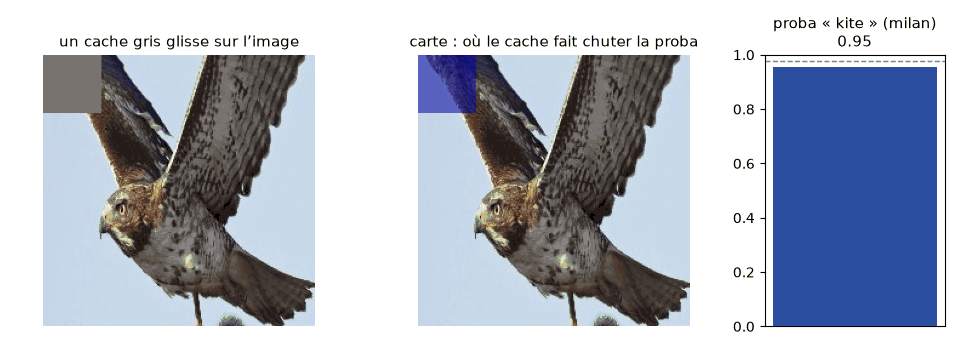</center>

Grad-CAM est une approximation par le gradient. L'**occlusion** fait l'expérience pour de vrai : on **cache** une partie de l'image et on mesure la chute de probabilité. Ci-dessus, la méthode sur une photo d'oiseau, avec ResNet-50 ImageNet.

La cellule fait la même chose sur l'A380 avec votre modèle C : un cache de 48 × 48 px, déplacé par pas de 24 px (64 positions). Puis deux masques faits main à partir du masque de l'avion :
- `sans_avion` : pixels de l'avion remplacés par la couleur du ciel ;
- `sans_ciel` : tout le reste remplacé par la couleur du ciel (`~mask` inverse le masque).

> ✏️ **À compléter** : construire `sans_avion` et `sans_ciel`, en partant de copies du tableau (`a.copy()`).

> 👀 **À regarder** : la zone chaude de la carte d'occlusion, comparée à la Grad-CAM de 4.1.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Le cache vaut 0 <b>après normalisation</b>, soit la couleur moyenne d'ImageNet, un gris neutre.</li>
<li>64 positions = 64 passages dans le réseau : l'occlusion est fiable mais coûteuse.</li>
</ul>
📖 article : <a href="https://arxiv.org/abs/1311.2901">Zeiler et Fergus, 2014</a> (section 4.2, <i>Occlusion Sensitivity</i>)
</details>

---
### ✍️ Réponse R10 — 2 pts

> **Prédiction, avant d'exécuter.** Lequel des deux masques (avion masqué / ciel masqué) fera le plus chuter la probabilité « avion » du modèle fine-tuné ? De combien, à la louche ? Pourquoi ?

C’est l’avion masqué qui fera le plus chuter la probabilité « avion ». Le ciel masqué devrait la laisser presque intacte. En 4.1, la Grad-CAM de C se concentrait sur le fuselage, les ailes et les moteurs, pas sur le ciel.

proba avion, image intacte : 0.997


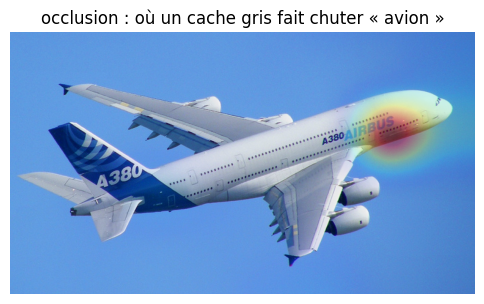

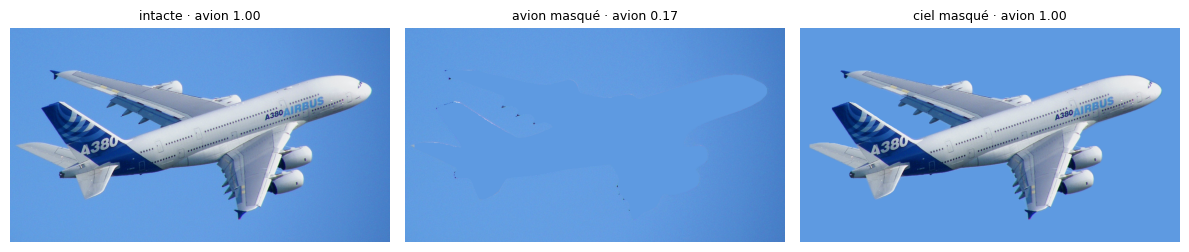

avion masqué : 0.168 · ciel masqué : 0.997
top-3 avion masqué : [('oiseau', 0.79), ('avion', 0.168), ('drone', 0.042)]


In [25]:
@torch.no_grad()
def prob_of(model, img, cls):
    return float(model(to_input(img).to(DEVICE)).softmax(1)[0, cls])

CLS_AVION = CLASSES.index('avion')
p0 = prob_of(model_diag, A380, CLS_AVION); print(f'proba avion, image intacte : {p0:.3f}')

# 1) carte d'occlusion : carré gris de 48 px glissé par pas de 24 sur le carré 224 ; valeur = chute de proba
def occlusion_map(model, img, cls, size=48, stride=24):
    x0 = to_input(img); n = (224 - size) // stride + 1; M = np.zeros((n, n))
    with torch.no_grad():
        for i in range(n):
            for j in range(n):
                x = x0.clone(); x[:, :, i*stride:i*stride+size, j*stride:j*stride+size] = 0   # 0 = gris moyen après normalisation
                M[i, j] = p0 - float(model(x.to(DEVICE)).softmax(1)[0, cls])
    return M

occ = occlusion_map(model_diag, A380, CLS_AVION)
show(overlay(A380, np.clip(occ, 0, None) / (occ.max() + 1e-8)), 'occlusion : où un cache gris fait chuter « avion »', size=6)

# 2) deux masques faits main, à partir du masque de l'avion
mask = np.asarray(Image.open(PHOTOS / 'a380_mask.png').convert('L')) > 127
a = np.asarray(A380); sky = a[:40, :200].reshape(-1, 3).mean(0).astype(np.uint8)
# Construisez `sans_avion` (pixels de l'avion remplacés par `sky`) et `sans_ciel` (tout sauf l'avion remplacé par `sky`).
b = a.copy(); b[mask] = sky;  sans_avion = Image.fromarray(b)   # pixels de l'avion → couleur du ciel
b = a.copy(); b[~mask] = sky; sans_ciel = Image.fromarray(b)    # tout sauf l'avion → couleur du ciel
pa, pc = prob_of(model_diag, sans_avion, CLS_AVION), prob_of(model_diag, sans_ciel, CLS_AVION)
show_grid([A380, sans_avion, sans_ciel], [f'intacte · avion {p0:.2f}', f'avion masqué · avion {pa:.2f}', f'ciel masqué · avion {pc:.2f}'], ncols=3, size=4)
print(f'avion masqué : {pa:.3f} · ciel masqué : {pc:.3f}')
with torch.no_grad(): t3 = model_diag(to_input(sans_avion).to(DEVICE)).softmax(1)[0].topk(3)
print('top-3 avion masqué :', [(CLASSES[i], round(float(v), 3)) for v, i in zip(*t3)])

In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""b = a.copy(); b[mask] = sky;  sans_avion = Image.fromarray(b)
b = a.copy(); b[~mask] = sky; sans_ciel = Image.fromarray(b)""")

---
### ✍️ Réponse R10 (suite) — 0 pt

> **Observation / explication.**
> - Résultat des deux masques ? Votre prédiction tenait-elle ?
> - Comparez la **carte d'occlusion** et la **carte Grad-CAM** de 4.1 : disent-elles la même chose ? Où divergent-elles ?
> - Laquelle des deux croyez-vous le plus, et pourquoi ? (Indice : l'une mesure un effet réel sur la sortie, l'autre une approximation linéaire locale.)

Résultats : avion masqué, la probabilité « avion » passe de 0,997 à 0,168, et le modèle prédit oiseau (0,79), sans doute à cause des petits points sombres restés dans le ciel. Ciel masqué, elle reste à 0,997. Ma prédiction tenait, avec une chute encore plus forte que prévu.
Occlusion vs Grad-CAM : les deux pointent l’avant du fuselage (nez et « AIRBUS »). Mais la Grad-CAM couvrait tout le centre de l’avion, alors que l’occlusion ne réagit qu’au nez : cacher un moteur ou la dérive ne change rien, le reste de l’avion suffit.
Laquelle croire : l’occlusion, car elle mesure un vrai effet sur la sortie, alors que Grad-CAM n’est qu’une approximation par le gradient. Elle sous-estime toutefois les parties redondantes.

### 4.7 🔧 Le patch adversarial du cours

Au lieu d'optimiser les **poids** pour que le réseau donne la bonne réponse, on peut optimiser une **image** pour qu'il donne celle qu'on veut. Ce carré de 177 × 177 px (10 % de la photo) a été calculé pour le cours : ResNet-50 ImageNet fixé, des centaines de pas de descente de gradient **sur les pixels du carré**, pour maximiser la classe `toaster`. L'avion reste parfaitement visible pour vous.

La cellule colle le patch sur l'A380 et compare le top-5 avant et après. Elle le montre aussi à votre modèle C, qui n'a jamais été visé et n'a pas de classe « toaster ».

> 👀 **À regarder** : le rang et la probabilité de `airliner` après le patch, et la réaction du modèle C.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Pendant l'optimisation, de petits décalages et flous aléatoires ont été ajoutés pour que le patch résiste aux redimensionnements.</li>
<li><code>Image.paste</code> colle le patch à la position <code>(421, 119)</code>, sur le fuselage.</li>
</ul>
📖 <a href="https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.paste">Image.paste</a> · article : <a href="https://arxiv.org/abs/1712.09665">Brown et al., Adversarial Patch, 2017</a>
</details>

surface du patch : 9.6%


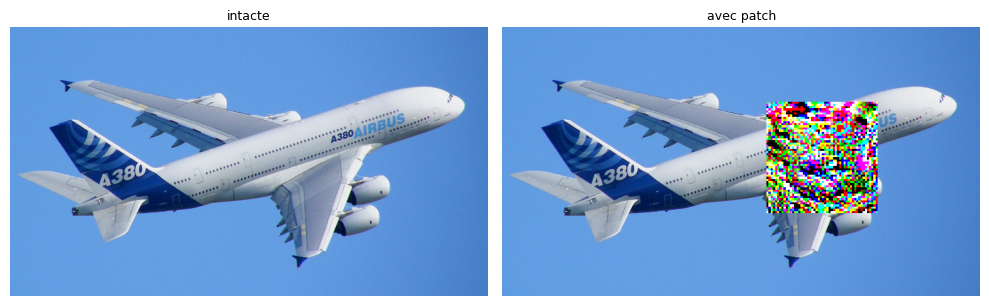


intacte :
   0.900  airliner
   0.086  wing
   0.007  space shuttle
   0.006  warplane
   0.001  projectile

avec patch :
   0.522  toaster
   0.109  airliner
   0.075  piggy bank
   0.055  warplane
   0.051  teapot

le même patch, vu par votre modèle à 3 classes : [('avion', 0.992), ('oiseau', 0.004), ('drone', 0.004)]


In [26]:
patch = Image.open(PHOTOS / 'patch_toaster.png').convert('RGB')
patched = A380.copy(); patched.paste(patch, (421, 119))
print('surface du patch :', f'{patch.size[0]*patch.size[1]/(A380.size[0]*A380.size[1]):.1%}')
show_grid([A380, patched], ['intacte', 'avec patch'], ncols=2, size=5)
for nom, im in [('intacte', A380), ('avec patch', patched)]:
    print(f'\n{nom} :'); [print(f'  {p:6.3f}  {n}') for n, p in top5(resnet, im)]
with torch.no_grad(): t3 = model_diag(to_input(patched).to(DEVICE)).softmax(1)[0].topk(3)
print('\nle même patch, vu par votre modèle à 3 classes :', [(CLASSES[i], round(float(v), 3)) for v, i in zip(*t3)])

---
### ✍️ Réponse R11 — 1.5 pts

> - Le patch occupe ~10 % de l'image, l'avion reste parfaitement visible pour vous, et la classe change. Qu'est-ce que cela révèle sur **ce que le réseau a appris** (par rapport à ce qu'un humain utilise) ?
> - Votre modèle à 3 classes est-il trompé par ce patch ? Pourquoi (ou pourquoi pas) ?
> - Donnez un cas d'usage aérospatial où ce type d'attaque est un vrai risque, et deux pistes de mitigation.

Ce que le réseau a appris : un patch de 9,6 % fait passer ResNet de airliner (0,90) à toaster (0,52), alors que l’avion reste entier. Le réseau ne raisonne pas sur la forme globale comme un humain : il additionne des motifs locaux, et une petite zone aux textures très fortes l’emporte sur tout le reste.
Mon modèle à 3 classes : il n’est pas trompé (avion 0,992 contre 0,997 sans patch). Le patch a été optimisé pour les poids de ResNet ImageNet et la classe toaster, que C n’a pas. Ses poids fine-tunés réagissent différemment. Mais un patch optimisé directement contre C pourrait le tromper aussi.
Cas d’usage et mitigation : une caméra anti-drone d’aéroport, où un drone portant un patch imprimé serait classé « oiseau » et ne déclencherait pas d’alerte. Pistes : un entraînement adversarial (ajouter des images patchées au train), et la fusion avec d’autres capteurs (radar, détection radio, thermique), qu’un patch visuel ne trompe pas.

### 4.9 🎁 Bonus : une perturbation naturelle

<center>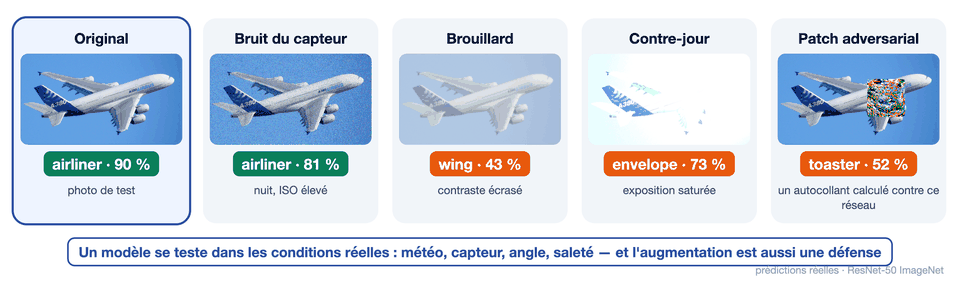</center>

Un capteur réel rencontre aussi des perturbations **naturelles** : brouillard, contre-jour, bruit, angle inhabituel. Concevez-en une, plausible dans la vraie vie, qui fait tomber `airliner` sous 50 %. La cellule donne un exemple de brouillard ; essayez aussi rotation, assombrissement, bruit.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li>Brouillard : mélange avec un gris clair (<code>a * 0.4 + 228 * 0.6</code>) puis léger flou. <code>np.clip(..., 0, 255)</code> ramène les valeurs dans l'intervalle autorisé.</li>
</ul>
📖 <a href="https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.rotate">Image.rotate</a> · <a href="https://pillow.readthedocs.io/en/stable/reference/ImageEnhance.html">ImageEnhance</a> · <a href="https://numpy.org/doc/stable/reference/generated/numpy.clip.html">numpy.clip</a> · article : <a href="https://arxiv.org/abs/1903.12261">Hendrycks et Dietterich, 2019</a>
</details>

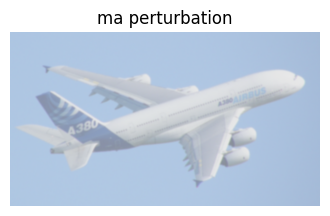

 0.374  airliner
 0.229  wing
 0.183  space shuttle
 0.138  airship
 0.060  warplane


In [27]:
a = np.asarray(A380).astype(float)
brouillard = Image.fromarray(np.clip(a * 0.4 + 228 * 0.6, 0, 255).astype(np.uint8)).filter(ImageFilter.GaussianBlur(1.5))
# essayez aussi : rotation (A380.rotate(90)), nuit (a*0.25), bruit (a + np.random.normal(0, 45, a.shape))…
ma_perturbation = brouillard
show(ma_perturbation, 'ma perturbation', size=4)
for n, p in top5(resnet, ma_perturbation): print(f'{p:6.3f}  {n}')

---
## Bloc 5 — Et pour la détection ? (25 min, maison)

Sur la photo de formation, il y a **quatre** avions : on veut savoir combien et où. C'est la **détection** : le réseau sort une liste de **boîtes**, chacune avec des coordonnées, une classe et une confiance.

### 5.1 🔧 YOLO sur la photo de formation

<center>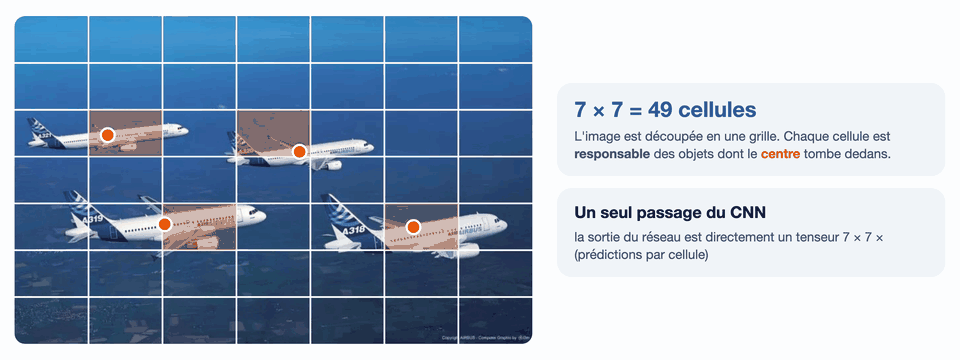</center>

YOLO découpe l'image en grille ; chaque case propose des boîtes. Deux filtres nettoient ces candidats :
1. le seuil de **confiance** `conf` (0,25 par défaut) jette les boîtes peu sûres ;
2. la **NMS** supprime les boîtes qui recouvrent une boîte plus confiante de même classe au-delà d'un **IoU** `iou` (0,7 par défaut).

**YOLO11n** (*nano*, 2,6 millions de poids) est entraîné sur COCO : 80 classes dont `airplane` et `bird`, mais pas `drone`. À 640 px, ses trois grilles (80², 40², 20²) font **8 400** candidats.

> 👀 **À regarder** : le nombre de boîtes, leurs classes et leurs confiances.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul>
<li><code>detect</code> appelle <code>yolo.predict(...)</code> et renvoie les boîtes <code>(x1, y1, x2, y2)</code> en pixels (coin haut-gauche, coin bas-droit), les confiances et les noms de classe.</li>
<li><code>draw</code> dessine les boîtes avec <code>ImageDraw</code>.</li>
<li>Au premier lancement, <code>YOLO('yolo11n.pt')</code> télécharge les poids (5,6 Mo) depuis Ultralytics (licence AGPL-3.0).</li>
</ul>
📖 <a href="https://docs.ultralytics.com/models/yolo11/">YOLO11</a> · <a href="https://docs.ultralytics.com/modes/predict/">mode Predict (conf, iou, imgsz)</a> · <a href="https://docs.ultralytics.com/modes/predict/#working-with-results">objet Results</a> · <a href="https://pillow.readthedocs.io/en/stable/reference/ImageDraw.html">ImageDraw</a>
</details>

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
4 boîtes : [('airplane', np.float32(0.92)), ('airplane', np.float32(0.88)), ('airplane', np.float32(0.87)), ('airplane', np.float32(0.84))]


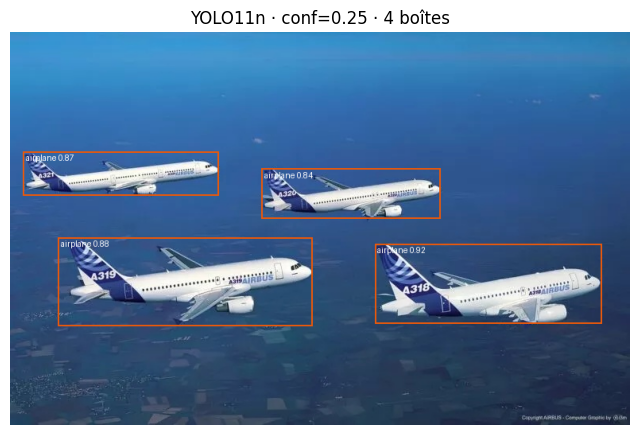

In [28]:
from ultralytics import YOLO
yolo = YOLO(str(DATA / 'yolo11n.pt')) if (DATA / 'yolo11n.pt').exists() else YOLO('yolo11n.pt')

def detect(img, conf=0.25, iou=0.7, imgsz=640):
    r = yolo.predict(img, conf=conf, iou=iou, imgsz=imgsz, verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), [r.names[int(c)] for c in r.boxes.cls]

def draw(img, boxes, confs, names, width=2, label=True):
    im = img.copy(); d = ImageDraw.Draw(im)
    for (x1, y1, x2, y2), c, n in zip(boxes, confs, names):
        d.rectangle([x1, y1, x2, y2], outline=(232, 89, 12), width=width)
        if label: d.text((x1 + 3, y1 + 2), f'{n} {c:.2f}', fill=(255, 255, 255))
    return im

boxes, confs, names = detect(FORMATION)
print(len(boxes), 'boîtes :', list(zip(names, confs.round(2))))
show(draw(FORMATION, boxes, confs, names), f'YOLO11n · conf=0.25 · {len(boxes)} boîtes', size=8)

### 5.2 ✏️ Le « bazar » des boîtes brutes

On regarde ce que YOLO produit **avant** le nettoyage : `conf=0.01` garde presque tout, `iou=1.0` désactive la NMS (deux boîtes ne se recouvrent jamais à plus de 100 %).

> ✏️ **À compléter** : deux appels à `detect`, l'un avec `conf=0.01, iou=1.0`, l'autre avec `conf=0.01, iou=0.7`.

> 👀 **À regarder** : combien de boîtes autour de chaque avion avant NMS, combien après, et s'il reste des boîtes sur le fond.

conf=0.01, iou=1.0 (sans NMS) : 47 boîtes
conf=0.01, iou=0.7 (avec NMS) : 5 boîtes


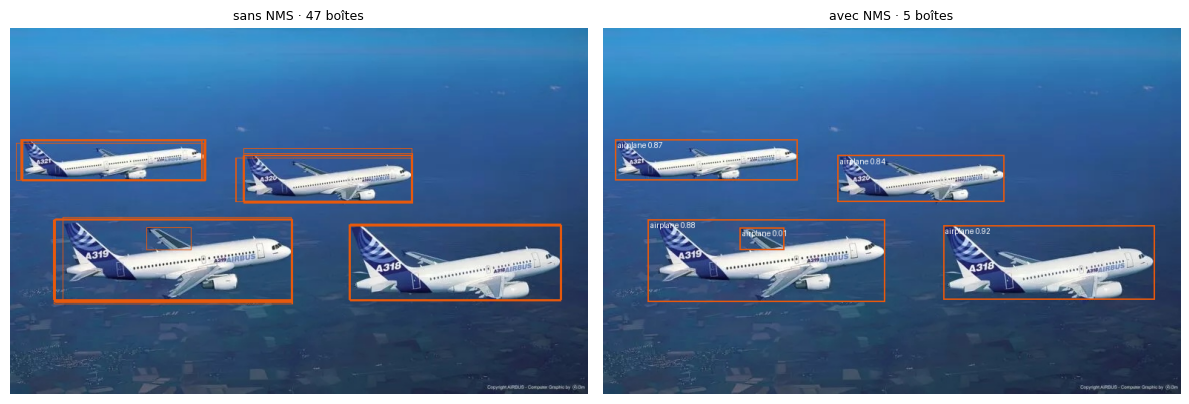

In [29]:
b_raw, c_raw, n_raw = detect(FORMATION, conf=0.01, iou=1.0)   # sans NMS
b_nms, c_nms, n_nms = detect(FORMATION, conf=0.01, iou=0.7)   # avec NMS
print(f'conf=0.01, iou=1.0 (sans NMS) : {len(b_raw)} boîtes')
print(f'conf=0.01, iou=0.7 (avec NMS) : {len(b_nms)} boîtes')
show_grid([draw(FORMATION, b_raw, c_raw, n_raw, width=1, label=False), draw(FORMATION, b_nms, c_nms, n_nms, width=2)],
          [f'sans NMS · {len(b_raw)} boîtes', f'avec NMS · {len(b_nms)} boîtes'], ncols=2, size=6)

In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""b_raw, c_raw, n_raw = detect(FORMATION, conf=0.01, iou=1.0)
b_nms, c_nms, n_nms = detect(FORMATION, conf=0.01, iou=0.7)""")

---
### ✍️ Réponse R12 — 1.5 pts

> - Combien de boîtes brutes ? Pourquoi autant, alors qu'il y a **4 avions** ? (Pensez à la grille et aux prédictions par cellule vues en cours.)
> - Que fait le passage `iou=1.0 → 0.7` sur ce nombre ? Décrivez la **NMS** en deux phrases avec **vos** chiffres.
> - Pourquoi reste-t-il peut-être encore des boîtes en trop (ou en moins) après NMS avec `conf=0.01` ?

Boîtes brutes : 47 boîtes sans NMS pour 4 avions. YOLO fait des prédictions sur 3 grilles (80², 40² et 20², soit 8 400 candidats), et chaque cellule proche d’un avion propose sa propre boîte. Le même avion est donc vu par plusieurs cellules voisines et à plusieurs échelles, ce qui donne environ 10 boîtes quasi identiques par avion (bien visibles en double trait sur la figure). conf=0.01 a déjà éliminé la plupart des candidats sur le fond.
NMS : passer iou de 1,0 à 0,7 fait tomber le nombre de boîtes de 47 à 5. La NMS garde la boîte la plus confiante, supprime toutes celles de même classe qui la recouvrent à plus de 70 % (IoU > 0,7), puis recommence avec la suivante.
Boîtes en trop : il reste une 5e boîte, « airplane 0,01 » sur l’aile de l’A319. Elle est petite à l’intérieur de la grande boîte, donc son IoU avec celle-ci est bien inférieur à 0,7 et la NMS ne la supprime pas. Seul le seuil de confiance peut l’éliminer : avec conf=0.25 (5.1), on retombe sur les 4 avions. À l’inverse, deux avions très proches pourraient se recouvrir à plus de 0,7 et l’un des deux serait supprimé à tort.

### 5.4 ✏️ Coder l'IoU une fois dans sa vie

<center>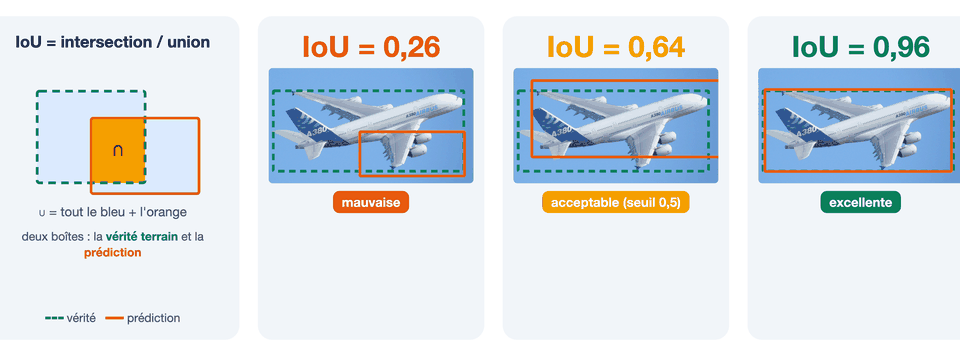</center>

$$\text{IoU}(A, B) = \frac{\text{aire}(A \cap B)}{\text{aire}(A) + \text{aire}(B) - \text{aire}(A \cap B)}$$

1 pour deux boîtes identiques, 0 pour deux boîtes disjointes. Elle sert dans la NMS et pour juger une prédiction (juste si IoU > 0,5 avec la vraie boîte, en général).

> ✏️ **À compléter**, avec des boîtes `(x1, y1, x2, y2)` : le coin haut-gauche de l'intersection est le **max** des deux coins haut-gauche, le coin bas-droit le **min** des deux coins bas-droit. Si la largeur ou la hauteur est négative, les boîtes ne se touchent pas : `max(0, ...)`.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
📖 <a href="https://pyimagesearch.com/2016/11/07/intersection-over-union-iou-for-object-detection/">IoU, explication illustrée</a> · <a href="https://docs.pytorch.org/vision/stable/generated/torchvision.ops.box_iou.html">torchvision.ops.box_iou</a> · <a href="https://docs.pytorch.org/vision/stable/generated/torchvision.ops.nms.html">torchvision.ops.nms</a>
</details>

In [31]:
def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])                 # coin haut-gauche de l'intersection
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])                 # coin bas-droit de l'intersection
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)               # 0 si les boîtes ne se touchent pas
    aire = lambda r: (r[2] - r[0]) * (r[3] - r[1])
    return inter / (aire(a) + aire(b) - inter + 1e-9)

# vérifications à la main
print('identiques      :', round(iou((0, 0, 10, 10), (0, 0, 10, 10)), 3), '(attendu 1.0)')
print('moitié décalée  :', round(iou((0, 0, 10, 10), (5, 0, 15, 10)), 3), '(attendu 0.333 : inter 50, union 150)')
print('disjointes      :', iou((0, 0, 10, 10), (20, 20, 30, 30)), '(attendu 0.0)')
# IoU entre les deux boîtes YOLO les plus confiantes de la photo
if len(b_raw) >= 2: print('deux boîtes brutes les plus confiantes (5.2) :', round(iou(b_raw[0], b_raw[1]), 3), '→ fusionnées par la NMS si > 0,7')

for conf in [0.01, 0.1, 0.25, 0.5, 0.85]:
    for s_iou in [0.3, 0.5, 0.7]:
        b, c, n = detect(FORMATION, conf=conf, iou=s_iou)
        print(f'conf={conf:<5} iou={s_iou} : {len(b)} boîtes')

identiques      : 1.0 (attendu 1.0)
moitié décalée  : 0.333 (attendu 0.333 : inter 50, union 150)
disjointes      : 0.0 (attendu 0.0)
deux boîtes brutes les plus confiantes (5.2) : 0.989 → fusionnées par la NMS si > 0,7
conf=0.01  iou=0.3 : 5 boîtes
conf=0.01  iou=0.5 : 5 boîtes
conf=0.01  iou=0.7 : 5 boîtes
conf=0.1   iou=0.3 : 4 boîtes
conf=0.1   iou=0.5 : 4 boîtes
conf=0.1   iou=0.7 : 4 boîtes
conf=0.25  iou=0.3 : 4 boîtes
conf=0.25  iou=0.5 : 4 boîtes
conf=0.25  iou=0.7 : 4 boîtes
conf=0.5   iou=0.3 : 4 boîtes
conf=0.5   iou=0.5 : 4 boîtes
conf=0.5   iou=0.7 : 4 boîtes
conf=0.85  iou=0.3 : 3 boîtes
conf=0.85  iou=0.5 : 3 boîtes
conf=0.85  iou=0.7 : 3 boîtes


In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area = lambda r: (r[2] - r[0]) * (r[3] - r[1])
    return inter / (area(a) + area(b) - inter + 1e-9)""")

---
### ✍️ Réponse R13 — 1 pt

> - Choisissez des valeurs de `conf` et `iou` pour **cette** photo de formation et justifiez-les (testez-les !).
> - Que donneraient ces mêmes seuils sur une photo d'**un seul avion** plein cadre ? Sur une photo de **40 oiseaux** en vol groupé ? Dans quel sens faudrait-il les bouger ?

Formation : conf=0.5, iou=0.5. D’après mes tests, conf=0.01 donne 5 boîtes (la boîte parasite sur l’aile), conf de 0,1 à 0,5 en donne 4 (les bons avions), et conf=0.85 en donne 3 (l’A320 à 0,84 disparaît). Avec 0,5, je suis au milieu de la plage correcte. iou ne change rien ici, de 0,3 à 0,7 : les avions ne se chevauchent pas et les doublons ont un IoU de 0,99 (5.4).
Un seul avion plein cadre : ces seuils fonctionnent aussi (confiance élevée, aucun voisin). On peut même monter conf pour supprimer les détections parasites sur des parties de l’avion.
40 oiseaux groupés : il s’agit de petits objets, avec des confiances plus faibles et des boîtes qui se chevauchent. Il faut baisser conf (vers 0,2) pour ne pas en rater et monter iou (vers 0,7 ou 0,8) pour que la NMS ne supprime pas des oiseaux voisins.

---
## Synthèse (15 min, maison)

Vous avez ouvert un CNN de trois façons : ses **activations** (bloc 2), ses **régimes d'apprentissage** (bloc 3), ses **décisions** (bloc 4). Relisez vos réponses et vos figures avant d'écrire : la synthèse s'appuie sur **vos** résultats.

---
### ✍️ Réponse R14 — 2 pts

> En **10 lignes maximum** : qu'est-ce qu'un CNN a appris, d'après ce que *vous* avez vu dans ce TP ? Chaque affirmation doit citer **une figure de votre notebook** (ex. « les cartes de conv1 en 2.4 ressemblent à des Sobel »).

Les premières couches détectent des motifs simples : les cartes de conv1 (2.4) réagissent aux bords et aux couleurs, comme Sobel et mon noyau fait main (1.4).
En montant, le champ réceptif grandit jusqu’à couvrir presque toute l’image en layer3 (2.8) : le réseau peut alors voir un objet entier.
Ces features sont réutilisables : le linear probe atteint 98,3 % avec 120 images, contre 68,3 % pour le modèle from scratch (3.7).
Mais un CNN apprend ce qui est corrélé à l’étiquette, pas forcément l’objet : A prend des oiseaux pour des drones en regardant les branches (4.3).
Même le bon modèle s’appuie sur peu de chose : seul le nez de l’A380 et l’inscription « AIRBUS » font chuter la probabilité à l’occlusion (4.5), et sans avion il voit un « oiseau » dans quelques points sombres (0,79).
Il reste fragile : un patch de 9,6 % transforme l’A380 en grille-pain pour ResNet (4.7).
En détection, il propose 47 boîtes pour 4 avions, et ce sont les seuils de confiance et la NMS qui font le tri (5.2).

---
### ✍️ Réponse R15 — 1 pt

> Quelle est la **première chose** que vous vérifierez dans votre projet CNN de l'autre matière, à la lumière de ce TP ? Une chose, concrète, et pourquoi celle-là.

Je vérifierai sur quoi mon modèle fonde ses décisions, en affichant la Grad-CAM de ses erreurs les plus confiantes. Dans ce TP, la val accuracy ne montrait pas que le modèle A regardait les branches au lieu de l’oiseau (4.3) : un bon score ne suffit pas si le train et la val partagent les mêmes biais.

Tu ne m’as pas envoyé les figures du bloc 2 : vérifie que les lignes 1 et 2 correspondent bien à tes cartes de la 2.4 et à tes mesures de la 2.8, et corrige-les si besoin. C’était la dernière question du TP.

---
## Barème

| Bloc | Réponses | Points |
|---|---|---|
| 1 Convolution | R1 (2), R2 (1) | 3 |
| 2 Couches | R3 (1,5), R4 (2), R5 (1,5) | 5 |
| 3 Transfer learning | R6 (3), R7 (1,5) | 4,5 |
| 4 Diagnostic | R8 (1), R9 (2,5), R10 (2), R11 (1,5) | 7 |
| 5 Détection | R12 (1,5), R13 (1) | 2,5 |
| Synthèse | R14 (2), R15 (1) | 3 |
| **Total** | | **25, ramené sur 20** |

Pour chaque réponse : **0** absente ou générique (ne cite pas la figure obtenue) · **½** observation juste mais explication fausse ou absente · **pleine** prédiction présente, observation reliée à la figure, explication cohérente avec le cours. Une prédiction fausse, assumée et expliquée, vaut la note pleine.